In [1]:
from pathlib import Path
import sys
import importlib

# Project root on Windows
root = Path(r"D:\suricata-ai-project")

if not (root / "src" / "netids").is_dir():
    raise FileNotFoundError(
        f"Cannot find netids package at {root}"
    )

src_path = str(root / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

importlib.invalidate_caches()

from netids.features.schema import (
    FEATURE_COLUMNS,
    validate_feature_matrix,
)
from netids.adapters.ctu import prepare_ctu13_flows
from netids.models.dl import NumpyMLP

print("=== JUPYTER ENVIRONMENT ===")
print("Python:", sys.executable)
print("Project:", root)
print("Feature columns:", FEATURE_COLUMNS)
print("NumpyMLP imported successfully")
print("PASS: Project imports")

=== JUPYTER ENVIRONMENT ===
Python: D:\suricata-ai-project\.venv\Scripts\python.exe
Project: D:\suricata-ai-project
Feature columns: ('protocol_tcp', 'duration_log', 'packets_log', 'bytes_log')
NumpyMLP imported successfully
PASS: Project imports


- Đây là stratified validation nằm bên trong Training. Nó giúp thử nghiệm thuật toán nhưng có thể chứa các Flow tương quan theo thời gian hoặc cùng host. Vì vậy, kết quả Validation chưa phải bằng chứng khả năng tổng quát hóa sang thiết bị mới.

In [2]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd

ctu_path = (
    root
    / "data"
    / "raw"
    / "ctu-13"
    / "capture20110815-2.binetflow"
)

if not ctu_path.is_file():
    raise FileNotFoundError(ctu_path)

ctu_raw = pd.read_csv(
    ctu_path,
    low_memory=False,
)

ctu_features = prepare_ctu13_flows(ctu_raw)

# Background has unknown target and is not used
labeled = (
    ctu_features.loc[
        ctu_features["target"].notna()
    ]
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Reproduce the original chronological 70/30 split
split_idx = int(len(labeled) * 0.70)

train_data = labeled.iloc[:split_idx].copy()

X_train = validate_feature_matrix(train_data)
y_train = train_data["target"].astype(int)

assert len(labeled) == 5577
assert len(X_train) == 3903
assert (y_train == 0).sum() == 3673
assert (y_train == 1).sum() == 230

print("=== INDEPENDENT NOTEBOOK DATA LOADING ===")
print("Labeled flows:", len(labeled))
print("Training flows:", len(X_train))
print("Feature columns:", X_train.columns.tolist())

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nPASS: Training data reconstructed.")
print("Original test set was not used.")

=== INDEPENDENT NOTEBOOK DATA LOADING ===
Labeled flows: 5577
Training flows: 3903
Feature columns: ['protocol_tcp', 'duration_log', 'packets_log', 'bytes_log']

Training class distribution:
target
0    3673
1     230
Name: count, dtype: int64

PASS: Training data reconstructed.
Original test set was not used.


In [4]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from netids.features.schema import validate_feature_matrix

# Split ONLY the original 3,903 training records.
# Do not touch the previous CTU-13 test set.
X_dev, X_val, y_dev, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42,
)

# Enforce feature names, values and canonical column order
X_dev = validate_feature_matrix(X_dev)
X_val = validate_feature_matrix(X_val)

# Fit scaler ONLY on development training data
mlp_scaler = StandardScaler()

X_dev_scaled = mlp_scaler.fit_transform(X_dev)
X_val_scaled = mlp_scaler.transform(X_val)

# Verify preparation
assert X_dev_scaled.shape[1] == 4
assert X_val_scaled.shape[1] == 4
assert len(X_dev_scaled) + len(X_val_scaled) == 3903

assert np.isfinite(X_dev_scaled).all()
assert np.isfinite(X_val_scaled).all()

assert set(np.unique(y_dev)) == {0, 1}
assert set(np.unique(y_val)) == {0, 1}

print("=== MLP DATA PREPARATION ===")
print("Development:", X_dev_scaled.shape)
print("Validation:", X_val_scaled.shape)

print("\nDevelopment class distribution:")
print(y_dev.value_counts().sort_index())

print("\nValidation class distribution:")
print(y_val.value_counts().sort_index())

print("\nPASS: MLP data prepared.")
print("Scaler fitted on Development only.")
print("Original CTU-13 test set untouched.")

=== MLP DATA PREPARATION ===
Development: (3122, 4)
Validation: (781, 4)

Development class distribution:
target
0    2938
1     184
Name: count, dtype: int64

Validation class distribution:
target
0    735
1     46
Name: count, dtype: int64

PASS: MLP data prepared.
Scaler fitted on Development only.
Original CTU-13 test set untouched.


In [5]:
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, confusion_matrix

# Huấn luyện MLP

mlp = NumpyMLP(
    input_dim=4,
    hidden1=16,
    hidden2=8,
    learning_rate=0.002,
    weight_decay=1e-4,
    epochs=150,
    batch_size=64,
    patience=20,
    random_state=42,
)

mlp.fit(
    X_dev_scaled,
    y_dev,
    X_val_scaled,
    y_val,
)

val_probs = mlp.predict_proba(X_val_scaled)[:, 1]
val_predictions = mlp.predict(X_val_scaled)

print("=== NUMPY MLP TRAINING ===")
print("Epochs executed:", mlp.epochs_ran_)
print("Best epoch:", mlp.best_epoch_)
print("Best weighted validation loss:",
      round(mlp.best_val_loss_, 6))

print("\n=== DEVELOPMENT VALIDATION ===")

print("Precision:", round(
    precision_score(y_val, val_predictions, zero_division=0),
    4,
))

print("Recall:", round(
    recall_score(y_val, val_predictions, zero_division=0),
    4,
))

print("F1:", round(
    f1_score(y_val, val_predictions, zero_division=0),
    4,
))

print("PR-AUC:", round(
    average_precision_score(y_val, val_probs),
    4,
))

print("\nConfusion matrix:")
print(confusion_matrix(
    y_val,
    val_predictions,
    labels=[0, 1],
))

print("\nStatus: DEVELOPMENT VALIDATION ONLY")

=== NUMPY MLP TRAINING ===
Epochs executed: 150
Best epoch: 146
Best weighted validation loss: 0.215181

=== DEVELOPMENT VALIDATION ===
Precision: 0.5059
Recall: 0.9348
F1: 0.6565
PR-AUC: 0.821

Confusion matrix:
[[693  42]
 [  3  43]]

Status: DEVELOPMENT VALIDATION ONLY


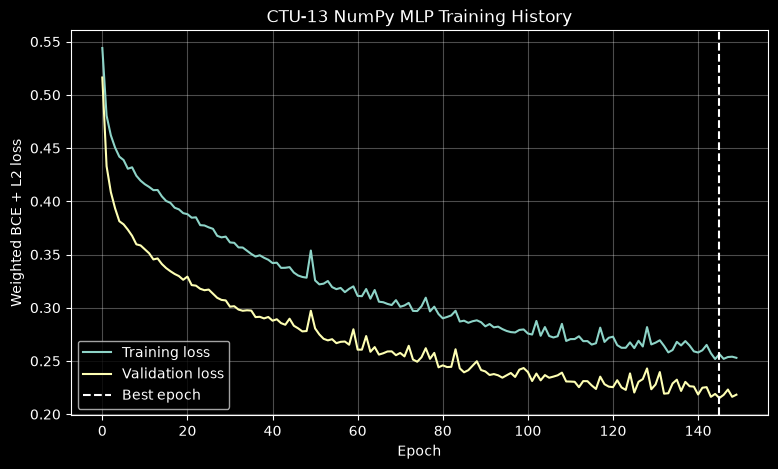

In [6]:
# Biểu đồ học của mạng Neural Network

import matplotlib.pyplot as plt

history = mlp.history_

plt.figure(figsize=(9, 5))

plt.plot(
    history["train_loss"],
    label="Training loss",
)

plt.plot(
    history["val_loss"],
    label="Validation loss",
)

plt.axvline(
    mlp.best_epoch_ - 1,
    linestyle="--",
    label="Best epoch",
)

plt.xlabel("Epoch")
plt.ylabel("Weighted BCE + L2 loss")
plt.title("CTU-13 NumPy MLP Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

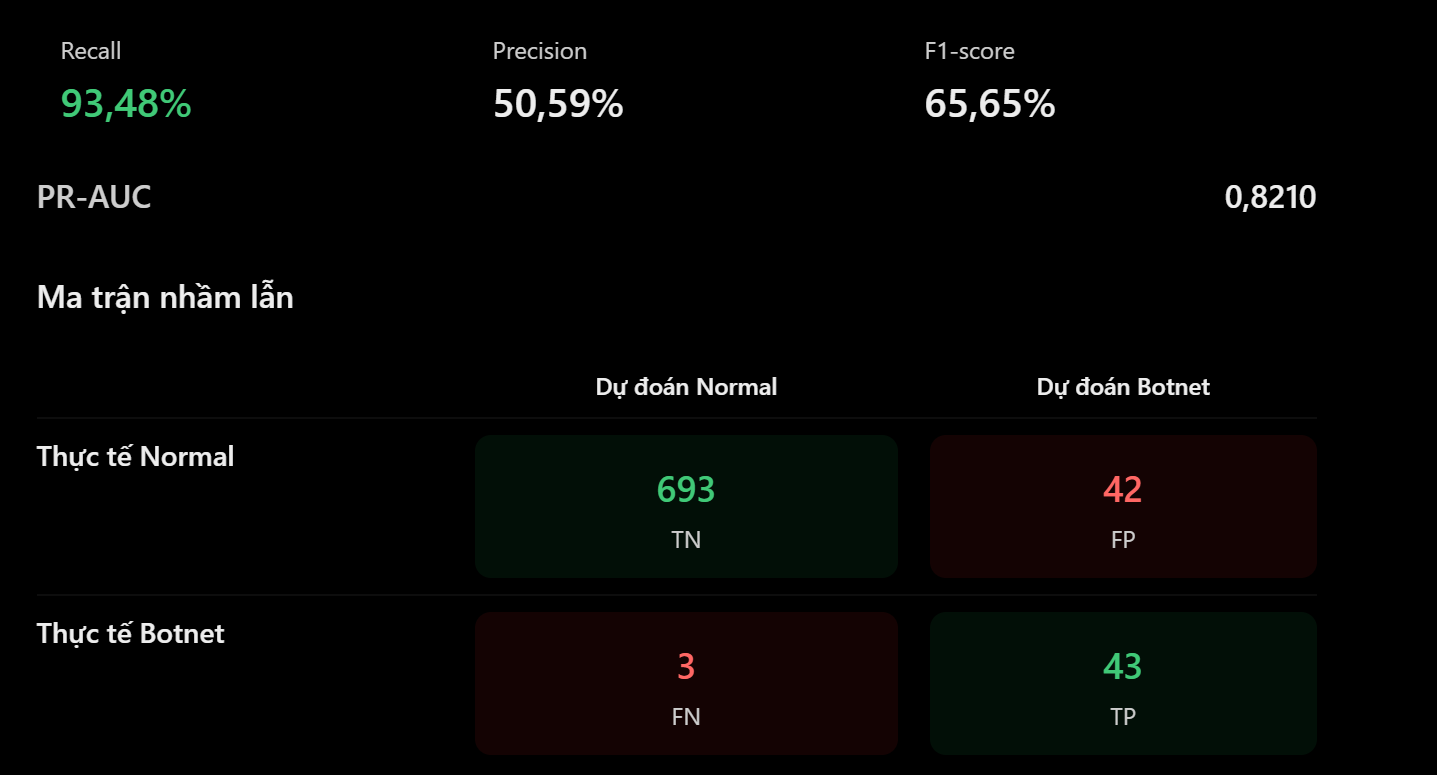

- Training Loss giảm tương đối đều, từ khoảng 0,54 xuống 0,25.
- Validation Loss giảm từ khoảng 0,52 xuống 0,22.
- Epoch tốt nhất nằm gần cuối quá trình huấn luyện, khoảng epoch 145.
- Chưa thấy dấu hiệu Overfitting rõ rệt từ hai đường Loss.
----
### Kết luận hiện tại: MLP đang học được tín hiệu phân loại hữu ích, nhưng vẫn tạo nhiều cảnh báo nhầm. Đặc biệt, phép chia Validation ngẫu nhiên có thể chứa Flow từ cùng host Botnet nên chưa chứng minh khả năng phát hiện tấn công mới.

In [7]:
# Kiểm tra Backpropagation bằng Numerical Gradient Checking
import numpy as np

from netids.models.dl import NumpyMLP

print("=== NUMPY MLP GRADIENT CHECK ===")

# Small independent network for testing derivatives
probe = NumpyMLP(
    input_dim=4,
    hidden1=5,
    hidden2=3,
    weight_decay=1e-4,
    random_state=42,
)

rng = np.random.default_rng(123)

X_gc = rng.normal(
    loc=0.0,
    scale=0.5,
    size=(8, 4),
)

y_gc = np.array(
    [0, 1, 0, 1, 0, 1, 0, 1],
    dtype=np.float64,
).reshape(-1, 1)

# Test class-weighted loss, not only unweighted BCE
weights_gc = np.where(
    y_gc == 1,
    2.0,
    1.0,
)

probe._initialize(np.random.default_rng(42))

cache = probe._forward(X_gc)

analytical_grads = probe._backward(
    cache,
    y_gc,
    weights_gc,
)

epsilon = 1e-5

total_parameters = 0
largest_error = 0.0

for name, parameter in probe.params_.items():

    numerical_grad = np.zeros_like(parameter)

    for idx in np.ndindex(parameter.shape):

        original = parameter[idx]

        parameter[idx] = original + epsilon

        plus_cache = probe._forward(X_gc)
        plus_loss = probe._loss(
            plus_cache["z3"],
            y_gc,
            weights_gc,
        )

        parameter[idx] = original - epsilon

        minus_cache = probe._forward(X_gc)
        minus_loss = probe._loss(
            minus_cache["z3"],
            y_gc,
            weights_gc,
        )

        parameter[idx] = original

        numerical_grad[idx] = (
            (plus_loss - minus_loss)
            / (2 * epsilon)
        )

    analytical = analytical_grads[name]

    max_error = float(np.max(
        np.abs(numerical_grad - analytical)
    ))

    largest_error = max(largest_error, max_error)
    total_parameters += parameter.size

    np.testing.assert_allclose(
        numerical_grad,
        analytical,
        rtol=1e-4,
        atol=1e-6,
        err_msg=f"Gradient mismatch: {name}",
    )

    print(
        f"{name}: "
        f"{parameter.size} parameters, "
        f"max error = {max_error:.3e}"
    )

print("\n=== RESULT ===")
print("Parameters checked:", total_parameters)
print("Largest absolute error:", largest_error)
print("PASS: NUMERICAL GRADIENT CHECK")


"""
    Ý tưởng: So sánh gradient do hàm _backward() tính với gradient xấp xỉ bằng cách thay đổi từng trọng số một lượng rất nhỏ.
    Nếu hai kết quả gần nhau, chúng ta có thêm bằng chứng công thức đạo hàm được triển khai đúng.
"""

=== NUMPY MLP GRADIENT CHECK ===
W1: 20 parameters, max error = 1.082e-11
b1: 5 parameters, max error = 5.285e-12
W2: 15 parameters, max error = 1.062e-11
b2: 3 parameters, max error = 2.980e-12
W3: 3 parameters, max error = 4.851e-12
b3: 1 parameters, max error = 2.890e-12

=== RESULT ===
Parameters checked: 47
Largest absolute error: 1.0816444961925242e-11
PASS: NUMERICAL GRADIENT CHECK


'\n    Ý tưởng: So sánh gradient do hàm _backward() tính với gradient xấp xỉ bằng cách thay đổi từng trọng số một lượng rất nhỏ.\n    Nếu hai kết quả gần nhau, chúng ta có thêm bằng chứng công thức đạo hàm được triển khai đúng.\n'

#### Hướng tiếp theo

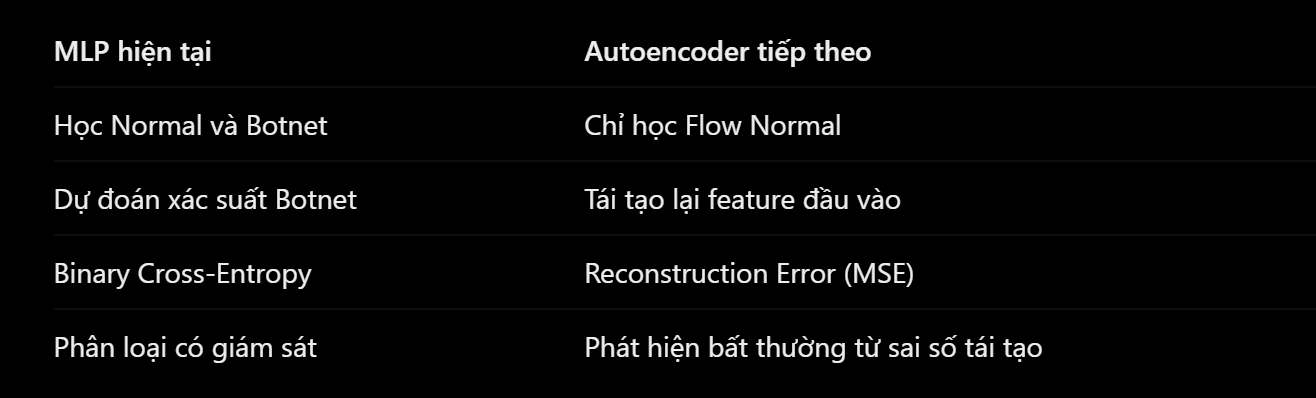

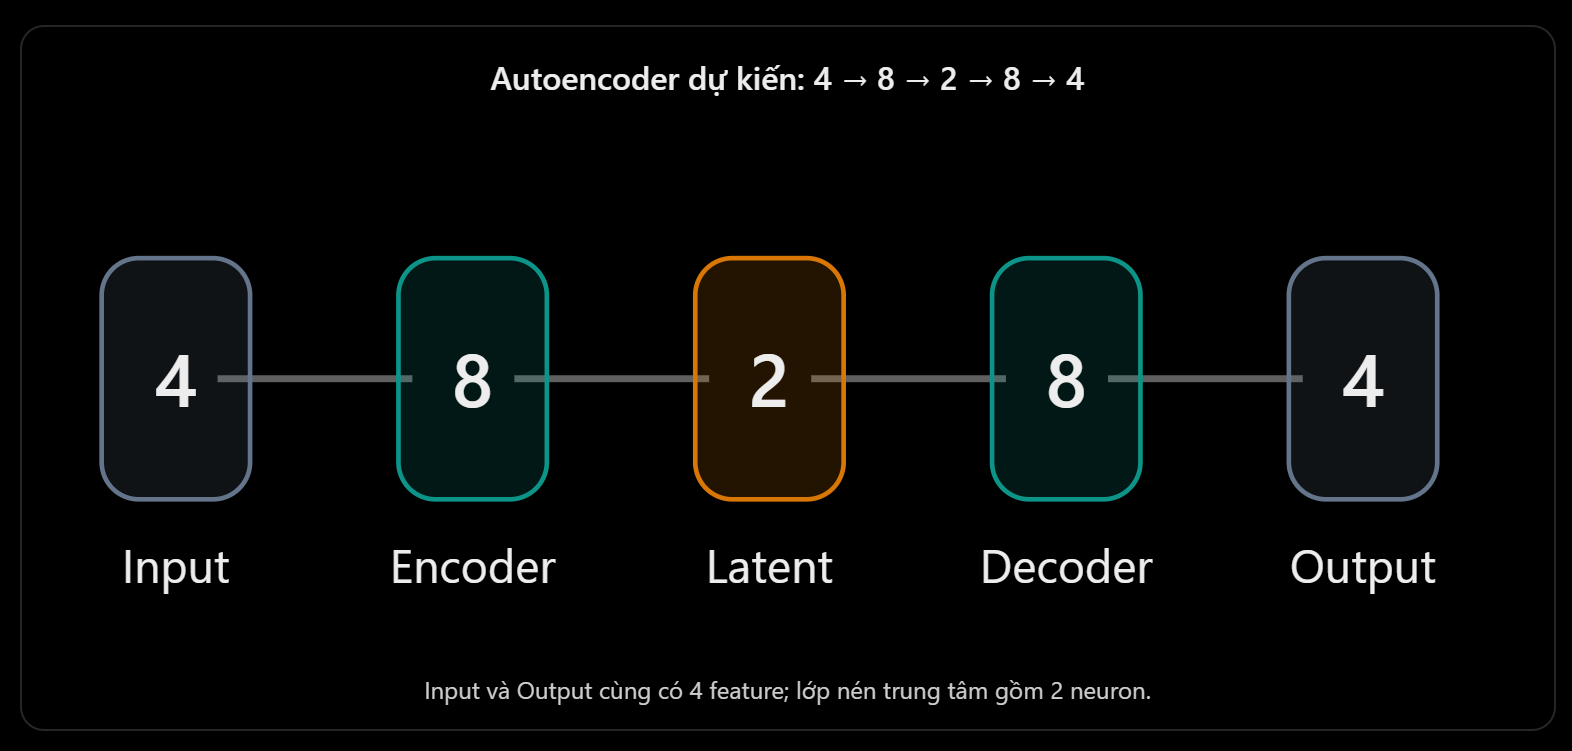

In [8]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from netids.features.schema import validate_feature_matrix
from netids.models.autoencoder import NumpyAutoencoder

print("=== AUTOENCODER DATA PREPARATION ===")

# Select only labeled Normal flows from Development
normal_mask = y_dev.eq(0)

X_normal_dev = validate_feature_matrix(
    X_dev.loc[normal_mask]
)

# Split Normal data into three independent subsets
# 70% training, 15% early stopping, 15% calibration
X_ae_train_raw, X_ae_reserved_raw = train_test_split(
    X_normal_dev,
    test_size=0.30,
    random_state=42,
    shuffle=True,
)

X_ae_stop_raw, X_ae_cal_raw = train_test_split(
    X_ae_reserved_raw,
    test_size=0.50,
    random_state=42,
    shuffle=True,
)

# Scaler learns statistics from Normal training ONLY
ae_scaler = StandardScaler()

X_ae_train = ae_scaler.fit_transform(
    X_ae_train_raw
)

X_ae_stop = ae_scaler.transform(
    X_ae_stop_raw
)

X_ae_cal = ae_scaler.transform(
    X_ae_cal_raw
)

# Mixed Normal + Botnet validation
# It is not used for fitting or threshold selection
X_ae_val = ae_scaler.transform(
    validate_feature_matrix(X_val)
)

y_ae_val = y_val.to_numpy(dtype=int)

assert (
    len(X_ae_train)
    + len(X_ae_stop)
    + len(X_ae_cal)
    == len(X_normal_dev)
)

assert set(np.unique(y_ae_val)) == {0, 1}

for array in (
    X_ae_train,
    X_ae_stop,
    X_ae_cal,
    X_ae_val,
):
    assert array.shape[1] == 4
    assert np.isfinite(array).all()

print("Normal training:", X_ae_train.shape)
print("Normal early stopping:", X_ae_stop.shape)
print("Normal calibration:", X_ae_cal.shape)
print("Mixed validation:", X_ae_val.shape)

print("\nValidation class counts:")
print(y_val.value_counts().sort_index())

print("\nPASS: AUTOENCODER DATA READY")
print("Scaler fitted on Normal training only.")
print("Original CTU-13 test set untouched.")

=== AUTOENCODER DATA PREPARATION ===
Normal training: (2056, 4)
Normal early stopping: (441, 4)
Normal calibration: (441, 4)
Mixed validation: (781, 4)

Validation class counts:
target
0    735
1     46
Name: count, dtype: int64

PASS: AUTOENCODER DATA READY
Scaler fitted on Normal training only.
Original CTU-13 test set untouched.


In [9]:
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
)

print("=== NUMPY AUTOENCODER TRAINING ===")

ae_model = NumpyAutoencoder(
    input_dim=4,
    hidden_dim=8,
    bottleneck_dim=2,
    learning_rate=0.002,
    weight_decay=1e-4,
    epochs=150,
    batch_size=64,
    patience=20,
    random_state=42,
)

ae_model.fit(
    X_ae_train,
    X_ae_stop,
)

print("Epochs executed:", ae_model.epochs_ran_)
print("Best epoch:", ae_model.best_epoch_)
print(
    "Best early-stopping loss:",
    round(ae_model.best_cal_loss_, 6),
)

# Threshold selection uses ONLY Normal calibration
cal_scores = ae_model.anomaly_score(X_ae_cal)

threshold = float(
    np.quantile(cal_scores, 0.99)
)

# Evaluation uses separate mixed validation
val_scores = ae_model.anomaly_score(X_ae_val)

val_pred = (val_scores > threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_ae_val,
    val_pred,
    labels=[0, 1],
).ravel()

fpr = fp / (fp + tn)

print("\n=== ANOMALY DETECTION THRESHOLD ===")
print("Calibration quantile:", 0.99)
print("Threshold:", threshold)
print("Normal calibration samples:", len(cal_scores))

print("\n=== DEVELOPMENT VALIDATION ===")

print(
    "Precision:",
    round(
        precision_score(
            y_ae_val,
            val_pred,
            zero_division=0,
        ),
        4,
    ),
)

print(
    "Recall:",
    round(
        recall_score(
            y_ae_val,
            val_pred,
            zero_division=0,
        ),
        4,
    ),
)

print(
    "F1:",
    round(
        f1_score(
            y_ae_val,
            val_pred,
            zero_division=0,
        ),
        4,
    ),
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_ae_val,
            val_scores,
        ),
        4,
    ),
)

print("FPR:", round(fpr, 4))

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_ae_val,
        val_pred,
        labels=[0, 1],
    )
)

print("\n=== RECONSTRUCTION ERROR ===")
print(
    "Normal median:",
    np.median(val_scores[y_ae_val == 0]),
)
print(
    "Botnet median:",
    np.median(val_scores[y_ae_val == 1]),
)

print("\nStatus: DEVELOPMENT VALIDATION ONLY")

=== NUMPY AUTOENCODER TRAINING ===
Epochs executed: 150
Best epoch: 150
Best early-stopping loss: 0.007808

=== ANOMALY DETECTION THRESHOLD ===
Calibration quantile: 0.99
Threshold: 0.04905755383198509
Normal calibration samples: 441

=== DEVELOPMENT VALIDATION ===
Precision: 0.52
Recall: 0.2826
F1: 0.3662
PR-AUC: 0.3161
FPR: 0.0163

Confusion matrix:
[[723  12]
 [ 33  13]]

=== RECONSTRUCTION ERROR ===
Normal median: 0.0010557545386365226
Botnet median: 0.013699810845632656

Status: DEVELOPMENT VALIDATION ONLY


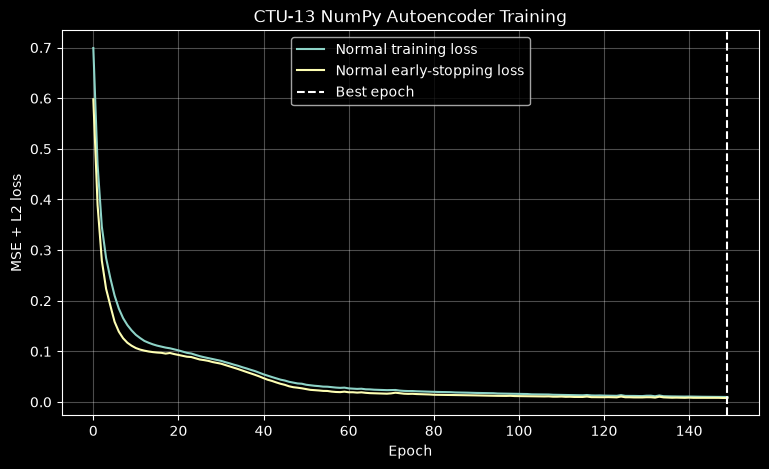

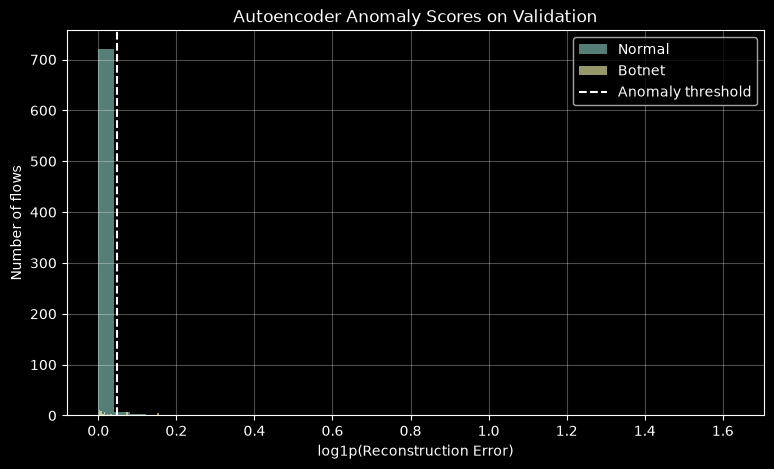

In [10]:
import matplotlib.pyplot as plt

# Training history
plt.figure(figsize=(9, 5))

plt.plot(
    ae_model.history_["train_loss"],
    label="Normal training loss",
)

plt.plot(
    ae_model.history_["cal_loss"],
    label="Normal early-stopping loss",
)

plt.axvline(
    ae_model.best_epoch_ - 1,
    linestyle="--",
    label="Best epoch",
)

plt.xlabel("Epoch")
plt.ylabel("MSE + L2 loss")
plt.title("CTU-13 NumPy Autoencoder Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Anomaly score distributions
normal_scores = val_scores[y_ae_val == 0]
botnet_scores = val_scores[y_ae_val == 1]

plt.figure(figsize=(9, 5))

# Logarithmic display helps visualize long-tailed errors
plt.hist(
    np.log1p(normal_scores),
    bins=40,
    alpha=0.6,
    label="Normal",
)

plt.hist(
    np.log1p(botnet_scores),
    bins=40,
    alpha=0.6,
    label="Botnet",
)

plt.axvline(
    np.log1p(threshold),
    linestyle="--",
    label="Anomaly threshold",
)

plt.xlabel("log1p(Reconstruction Error)")
plt.ylabel("Number of flows")
plt.title("Autoencoder Anomaly Scores on Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    average_precision_score,
)

print("=== AUTOENCODER ERROR ANALYSIS ===")

# Ensure scores, labels and original features are aligned
assert len(X_val) == len(y_ae_val) == len(val_scores)
assert np.array_equal(
    y_val.to_numpy(dtype=int),
    np.asarray(y_ae_val, dtype=int),
)

audit = pd.DataFrame({
    "protocol": np.where(
        X_val["protocol_tcp"].to_numpy() == 1,
        "TCP",
        "UDP",
    ),
    "target": np.asarray(y_ae_val, dtype=int),
    "score": np.asarray(val_scores, dtype=float),
})

audit["predicted"] = (
    audit["score"] > threshold
).astype(int)

audit["class"] = audit["target"].map({
    0: "Normal",
    1: "Botnet",
})

rows = []

for proto, part in audit.groupby("protocol"):
    tn, fp, fn, tp = confusion_matrix(
        part["target"],
        part["predicted"],
        labels=[0, 1],
    ).ravel()

    rows.append({
        "Protocol": proto,
        "Normal": int(tn + fp),
        "Botnet": int(tp + fn),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Recall": (
            tp / (tp + fn) if tp + fn else np.nan
        ),
        "FPR": (
            fp / (fp + tn) if fp + tn else np.nan
        ),
        "PR-AUC": (
            average_precision_score(
                part["target"],
                part["score"],
            )
            if part["target"].nunique() == 2
            else np.nan
        ),
    })

protocol_report = pd.DataFrame(rows)

print("\n=== PERFORMANCE BY PROTOCOL ===")
display(protocol_report.round(4))

print("\n=== RECONSTRUCTION ERROR QUANTILES ===")

quantile_report = (
    audit.groupby("class")["score"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
    .unstack()
)

display(quantile_report.round(6))

print("\n=== CALIBRATION SCORE QUANTILES ===")

calibration_quantiles = pd.Series({
    "P50": np.quantile(cal_scores, 0.50),
    "P90": np.quantile(cal_scores, 0.90),
    "P95": np.quantile(cal_scores, 0.95),
    "P99": np.quantile(cal_scores, 0.99),
    "Maximum": np.max(cal_scores),
})

display(calibration_quantiles.to_frame("Score").round(6))

print("\nFixed threshold:", round(threshold, 6))
print("Total validation flows:", len(audit))
print("Total alerts:", int(audit["predicted"].sum()))

print("\nPASS: AUTOENCODER DIAGNOSTIC COMPLETED")

=== AUTOENCODER ERROR ANALYSIS ===

=== PERFORMANCE BY PROTOCOL ===


,Protocol,Normal,Botnet,TP,FP,FN,TN,Recall,FPR,PR-AUC
0,TCP,255,43,13,11,30,244,0.3023,0.0431,0.3575
1,UDP,480,3,0,1,3,479,0.0000,0.0021,0.0334



=== RECONSTRUCTION ERROR QUANTILES ===


,0.50,0.75,0.90,0.95,0.99,1.00
class,,,,,,
Botnet,0.013700,0.070560,0.120963,0.167432,0.176547,0.183313
Normal,0.001056,0.004372,0.010625,0.018165,0.093185,4.076426



=== CALIBRATION SCORE QUANTILES ===


,Score
P50,0.001357
P90,0.012181
P95,0.022437
P99,0.049058
Maximum,0.147266



Fixed threshold: 0.049058
Total validation flows: 781
Total alerts: 25

PASS: AUTOENCODER DIAGNOSTIC COMPLETED


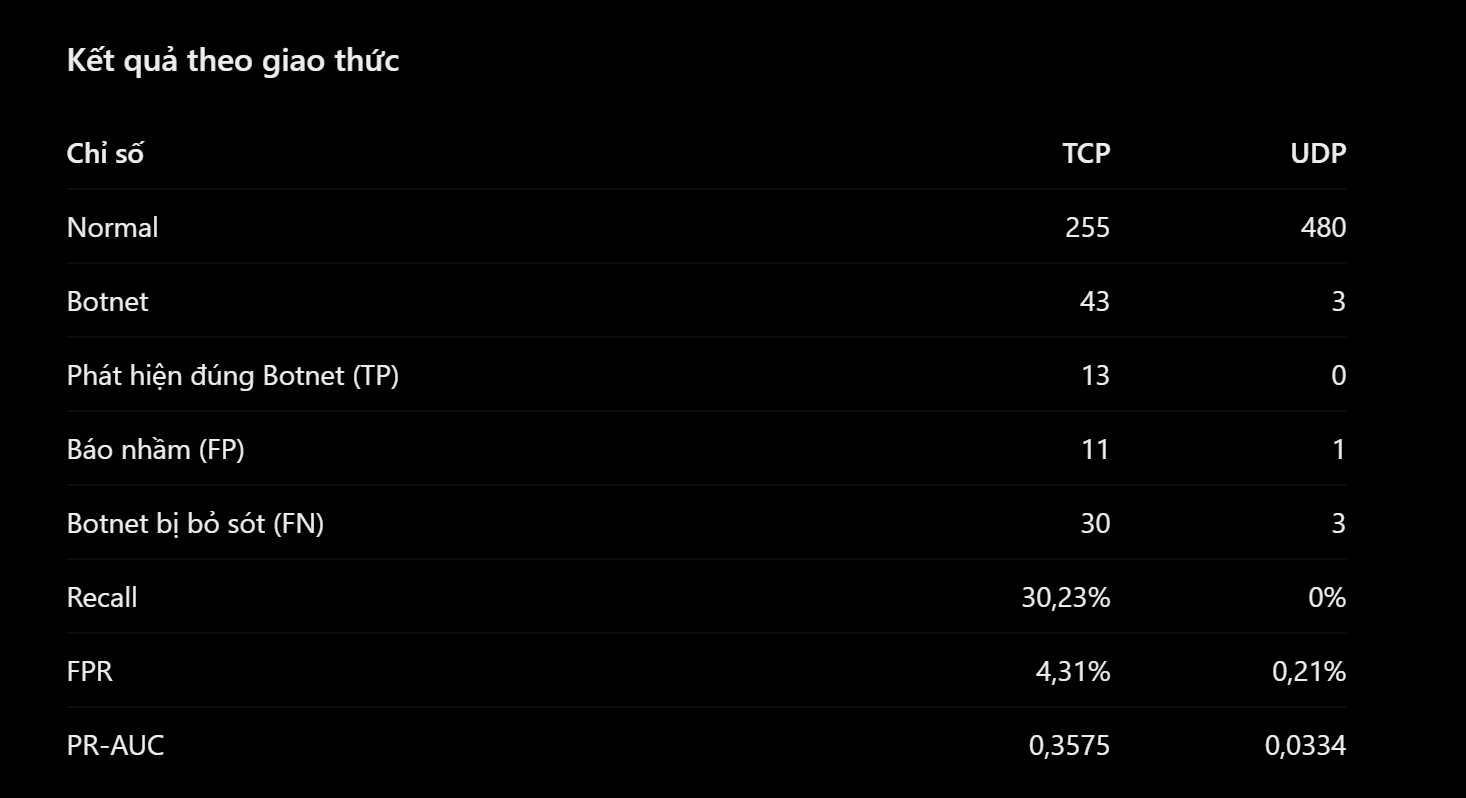

Ba phát hiện đáng ghi vào báo cáo:
1. TCP là nguồn chính của các cảnh báo. Có 11/12 False Positive thuộc TCP, đồng thời 13/13 True Positive cũng thuộc TCP.
2. UDP chưa có khả năng phát hiện đáng tin cậy. Mô hình bỏ sót cả 3 Flow Botnet UDP. Tuy nhiên, số mẫu dương tính quá nhỏ để kết luận về hiệu năng UDP nói chung.
3. Ngưỡng 0,049058 đang đánh đổi Recall để giảm cảnh báo nhầm. Trong 781 Flow Validation, mô hình chỉ đưa ra 25 cảnh báo, gồm 13 đúng và 12 sai.
Phát hiện đặc biệt: Normal có Reconstruction Error rất lớn
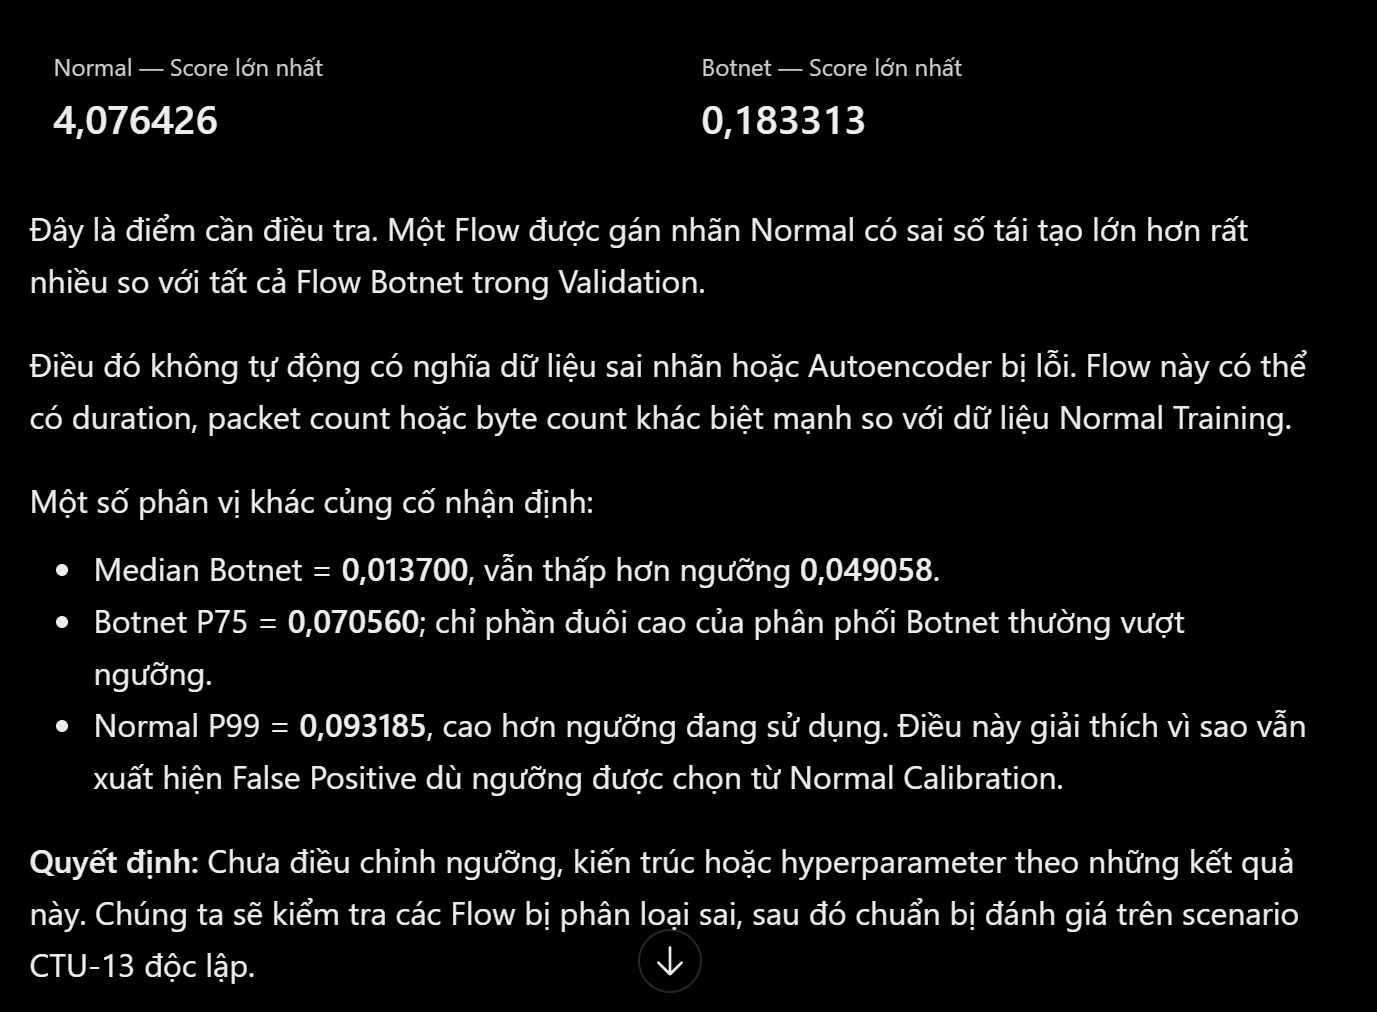

In [12]:
import numpy as np
import pandas as pd

print("=== AUTOENCODER FLOW-LEVEL ERROR AUDIT ===")

# X_val retains the indices from the original training data.
assert X_val.index.is_unique
assert train_data.index.is_unique
assert X_val.index.isin(train_data.index).all()

metadata_columns = [
    "timestamp",
    "SrcAddr",
    "DstAddr",
    "protocol",
    "duration_s",
    "total_packets",
    "total_bytes",
]

audit_flows = (
    train_data.loc[X_val.index, metadata_columns]
    .copy()
    .reset_index(drop=True)
)

audit_flows["target"] = np.asarray(
    y_ae_val, dtype=int
)

audit_flows["score"] = np.asarray(
    val_scores, dtype=float
)

audit_flows["predicted"] = (
    audit_flows["score"] > threshold
).astype(int)

# Attach original model feature values
X_aligned = X_val.reset_index(drop=True)

for feature in [
    "duration_log",
    "packets_log",
    "bytes_log",
]:
    audit_flows[feature] = X_aligned[feature]

# Validate alignment
assert len(audit_flows) == 781

assert np.array_equal(
    audit_flows["target"].to_numpy(),
    y_val.to_numpy(dtype=int),
)

fp_flows = audit_flows.loc[
    (audit_flows["target"] == 0)
    & (audit_flows["predicted"] == 1)
]

fn_flows = audit_flows.loc[
    (audit_flows["target"] == 1)
    & (audit_flows["predicted"] == 0)
]

print("\n=== TOP FALSE POSITIVES ===")
print("Total FP:", len(fp_flows))

display(
    fp_flows
    .sort_values("score", ascending=False)
    .head(10)
    .round(6)
)

print("\n=== MOST NORMAL-LIKE MISSED BOTNET FLOWS ===")
print("Total FN:", len(fn_flows))

display(
    fn_flows
    .sort_values("score", ascending=True)
    .head(10)
    .round(6)
)

print("\n=== HIGHEST SCORE BY TRUE CLASS ===")

display(
    audit_flows
    .sort_values("score", ascending=False)
    .groupby("target", sort=True)
    .head(3)
    .sort_values(["target", "score"], ascending=[True, False])
    .round(6)
)

print("\nThreshold:", round(threshold, 6))
print("PASS: FLOW-LEVEL ERROR AUDIT COMPLETED")

=== AUTOENCODER FLOW-LEVEL ERROR AUDIT ===

=== TOP FALSE POSITIVES ===
Total FP: 12


C:\Users\ASUS-PRO\AppData\Local\Temp\ipykernel_28812\4208669351.py:74: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(6)


,timestamp,SrcAddr,DstAddr,protocol,duration_s,total_packets,total_bytes,target,score,predicted,duration_log,packets_log,bytes_log
730,2011-08-15 16:43:21.022991,74.125.108.212,147.32.84.118,tcp,1805.375000,104956,137416417,0,4.076426,1,7.499077,11.561306,18.738526
190,2011-08-15 16:53:44.725844,147.32.84.170,209.85.149.116,tcp,255.862915,14673,15462777,0,1.049314,1,5.548543,9.593832,16.553946
249,2011-08-15 16:48:02.831707,147.32.84.170,209.85.149.117,tcp,247.736542,7759,6959417,0,0.594171,1,5.516394,8.956738,15.755606
532,2011-08-15 16:50:46.099770,147.32.84.134,209.85.149.132,tcp,308.420074,4143,3908443,0,0.319456,1,5.734700,8.329417,15.178650
729,2011-08-15 16:43:39.276524,147.32.84.232,82.208.56.89,udp,1063.999146,4,360,0,0.178414,1,6.970729,1.609438,5.888878
47,2011-08-15 16:57:29.303624,147.32.84.134,78.24.14.16,tcp,0.071100,298,300045,0,0.136487,1,0.068686,5.700444,12.611691
508,2011-08-15 16:55:59.073488,147.32.84.164,194.79.52.199,tcp,148.509018,1200,1313493,0,0.113134,1,5.007357,7.090910,14.088201
214,2011-08-15 16:56:32.167402,147.32.84.164,209.85.149.132,tcp,350.513519,931,623125,0,0.102437,1,5.862248,6.837333,13.342504
471,2011-08-15 16:52:01.230024,147.32.84.170,72.21.214.143,tcp,309.452759,40,30517,0,0.075225,1,5.738032,3.713572,10.326072
237,2011-08-15 16:56:12.141584,147.32.84.164,194.79.52.199,tcp,135.280228,16,7571,0,0.071039,1,4.914713,2.833213,8.932213



=== MOST NORMAL-LIKE MISSED BOTNET FLOWS ===
Total FN: 33


C:\Users\ASUS-PRO\AppData\Local\Temp\ipykernel_28812\4208669351.py:84: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(6)


,timestamp,SrcAddr,DstAddr,protocol,duration_s,total_packets,total_bytes,target,score,predicted,duration_log,packets_log,bytes_log
416,2011-08-15 16:58:35.905781,147.32.84.165,65.54.186.47,tcp,2.058743,28,13044,1,0.000796,0,1.118004,3.367296,9.476160
58,2011-08-15 16:54:40.508584,147.32.84.165,147.32.80.9,udp,0.000364,2,182,1,0.001687,0,0.000364,1.098612,5.209486
141,2011-08-15 17:00:11.979690,147.32.84.165,65.54.186.10,tcp,1.811403,37,23301,1,0.001695,0,1.033684,3.637586,10.056294
115,2011-08-15 16:58:10.899245,147.32.84.165,74.3.164.223,tcp,101.678993,114,91426,1,0.002466,0,4.631608,4.744932,11.423296
777,2011-08-15 17:00:54.054361,147.32.84.165,212.117.171.138,tcp,5.437830,23,5350,1,0.002828,0,1.862192,3.178054,8.585039
83,2011-08-15 16:54:33.145410,147.32.84.165,147.32.80.9,udp,0.444166,2,202,1,0.003626,0,0.367532,1.098612,5.313206
415,2011-08-15 16:58:03.780086,147.32.84.165,212.117.171.138,tcp,3.174228,35,12681,1,0.003899,0,1.428929,3.583519,9.447939
566,2011-08-15 17:00:52.671203,147.32.84.165,65.55.255.9,tcp,0.842671,29,18312,1,0.004003,0,0.611216,3.401197,9.815366
504,2011-08-15 16:58:07.642375,147.32.84.165,65.54.234.24,tcp,1.119625,16,6134,1,0.004589,0,0.751239,2.833213,8.721765
44,2011-08-15 16:58:24.168557,147.32.84.165,212.117.171.138,tcp,2.908246,34,11619,1,0.004883,0,1.363089,3.555348,9.360483



=== HIGHEST SCORE BY TRUE CLASS ===


C:\Users\ASUS-PRO\AppData\Local\Temp\ipykernel_28812\4208669351.py:95: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(6)


,timestamp,SrcAddr,DstAddr,protocol,duration_s,total_packets,total_bytes,target,score,predicted,duration_log,packets_log,bytes_log
730,2011-08-15 16:43:21.022991,74.125.108.212,147.32.84.118,tcp,1805.375000,104956,137416417,0,4.076426,1,7.499077,11.561306,18.738526
190,2011-08-15 16:53:44.725844,147.32.84.170,209.85.149.116,tcp,255.862915,14673,15462777,0,1.049314,1,5.548543,9.593832,16.553946
249,2011-08-15 16:48:02.831707,147.32.84.170,209.85.149.117,tcp,247.736542,7759,6959417,0,0.594171,1,5.516394,8.956738,15.755606
615,2011-08-15 17:00:52.472036,147.32.84.165,212.117.171.138,tcp,27.389126,104,11432,1,0.183313,1,3.346006,4.653960,9.344259
689,2011-08-15 16:56:08.212666,147.32.84.165,61.178.56.36,tcp,3.003704,2,124,1,0.168277,1,1.387220,1.098612,4.828314
34,2011-08-15 16:58:05.632547,147.32.84.165,61.17.216.93,tcp,2.952842,2,124,1,0.167432,1,1.374435,1.098612,4.828314



Threshold: 0.049058
PASS: FLOW-LEVEL ERROR AUDIT COMPLETED


In [13]:
# Kiểm tra ranh giới thời gian Train/Test

import pandas as pd
import numpy as np

print("=== CTU-13 TEMPORAL BOUNDARY AUDIT ===")

# Reconstruct the original chronological split
# from Notebook 07.
assert len(labeled) == 5577
assert split_idx == 3903

train_time_audit = labeled.iloc[:split_idx].copy()
test_time_audit = labeled.iloc[split_idx:].copy()

# The earliest StartTime assigned to Testing
test_start = test_time_audit["timestamp"].min()

# Estimate flow end using StartTime + Duration
train_time_audit["end_timestamp"] = (
    train_time_audit["timestamp"]
    + pd.to_timedelta(
        train_time_audit["duration_s"],
        unit="s",
    )
)

train_time_audit["crosses_boundary"] = (
    train_time_audit["end_timestamp"] > test_start
)

crossing = train_time_audit.loc[
    train_time_audit["crosses_boundary"]
].copy()

print("Training flows:", len(train_time_audit))
print("Testing flows:", len(test_time_audit))
print("First Testing StartTime:", test_start)

print("\n=== CROSS-BOUNDARY FLOWS ===")
print("Total crossing:", len(crossing))
print(
    "Percentage of Training:",
    round(
        100 * len(crossing) / len(train_time_audit),
        4,
    ),
    "%",
)

print("\n=== CROSSING BY CLASS AND PROTOCOL ===")

report = (
    train_time_audit
    .groupby(["target", "protocol"])["crosses_boundary"]
    .agg(
        total="size",
        crossing="sum",
    )
    .reset_index()
)

report["crossing_pct"] = (
    100 * report["crossing"] / report["total"]
)

display(report.round(4))

print("\n=== LONGEST CROSS-BOUNDARY FLOWS ===")

if len(crossing) > 0:

    crossing["overlap_seconds"] = (
        crossing["end_timestamp"] - test_start
    ).dt.total_seconds()

    columns = [
        "timestamp",
        "end_timestamp",
        "SrcAddr",
        "DstAddr",
        "protocol",
        "target",
        "duration_s",
        "total_packets",
        "total_bytes",
        "overlap_seconds",
    ]

    display(
        crossing
        .sort_values(
            "overlap_seconds",
            ascending=False,
        )
        [columns]
        .head(10)
    )

    print(
        "Maximum overlap (seconds):",
        round(
            crossing["overlap_seconds"].max(),
            3,
        ),
    )

else:
    print("No Training flow crosses the Test boundary.")

print("\nPASS: TEMPORAL BOUNDARY AUDIT COMPLETED")
print("No model or dataset modifications performed.")

=== CTU-13 TEMPORAL BOUNDARY AUDIT ===
Training flows: 3903
Testing flows: 1674
First Testing StartTime: 2011-08-15 17:01:00.835099

=== CROSS-BOUNDARY FLOWS ===
Total crossing: 167
Percentage of Training: 4.2788 %

=== CROSSING BY CLASS AND PROTOCOL ===


,target,protocol,total,crossing,crossing_pct
0,0,tcp,1375,149,10.8364
1,0,udp,2298,12,0.5222
2,1,tcp,208,6,2.8846
3,1,udp,22,0,0.0000



=== LONGEST CROSS-BOUNDARY FLOWS ===


,timestamp,end_timestamp,SrcAddr,DstAddr,protocol,target,duration_s,total_packets,total_bytes,overlap_seconds
1,2011-08-15 16:43:21.022991,2011-08-15 17:13:26.397991,74.125.108.212,147.32.84.118,tcp,0,1805.375000,104956,137416417,745.562892
191,2011-08-15 16:46:25.724602,2011-08-15 17:13:25.961663,147.32.84.170,64.12.73.133,tcp,0,1620.237061,74,4440,745.126564
190,2011-08-15 16:46:25.724549,2011-08-15 17:13:25.843690,147.32.84.170,64.12.73.165,tcp,0,1620.119141,88,6858,745.008591
3594,2011-08-15 17:00:17.504678,2011-08-15 17:13:18.222024,147.32.84.170,209.85.148.105,tcp,0,780.717346,181,71462,737.386925
113,2011-08-15 16:44:42.432258,2011-08-15 17:13:16.074348,147.32.84.8,82.208.56.89,udp,0,1713.642090,20,1800,735.239249
53,2011-08-15 16:43:42.995847,2011-08-15 17:13:09.273069,147.32.86.96,82.208.56.89,udp,0,1766.277222,112,10080,728.437970
371,2011-08-15 16:47:55.380071,2011-08-15 17:13:02.919011,147.32.84.13,82.208.56.89,udp,0,1507.538940,96,8640,722.083912
65,2011-08-15 16:43:48.313333,2011-08-15 17:13:01.447977,147.32.84.170,91.189.89.114,tcp,0,1753.134644,60,6624,720.612878
82,2011-08-15 16:43:54.725357,2011-08-15 17:12:54.819107,147.32.84.170,88.86.102.50,tcp,0,1740.093750,190,41238,713.984008
2,2011-08-15 16:43:21.410500,2011-08-15 17:12:48.302102,147.32.84.170,74.125.39.125,tcp,0,1766.891602,92,7530,707.467003


Maximum overlap (seconds): 745.563

PASS: TEMPORAL BOUNDARY AUDIT COMPLETED
No model or dataset modifications performed.


In [14]:
from netids.features.splitting import (
    purged_chronological_split,
)

print("=== PURGED CHRONOLOGICAL SPLIT ===")

purged_train, fixed_test, split_report = (
    purged_chronological_split(
        labeled,
        train_fraction=0.70,
    )
)

for name, value in split_report.items():
    print(f"{name}: {value}")

print("\n=== PURGED TRAIN CLASS DISTRIBUTION ===")
print(
    purged_train["target"]
    .value_counts()
    .sort_index()
)

# Original split must stay unchanged
assert split_report["original_train"] == 3903
assert split_report["test"] == 1674
assert split_report["overlap_removed"] == 167

# Verify that retained training flows end on time
end_times = (
    purged_train["timestamp"]
    + pd.to_timedelta(
        purged_train["duration_s"],
        unit="s",
    )
)

assert (
    end_times <= split_report["boundary"]
).all()

print("\nPASS: PURGED SPLIT VALIDATED")
print("Original models and test metrics unchanged.")

=== PURGED CHRONOLOGICAL SPLIT ===
boundary: 2011-08-15 17:01:00.835099
original_train: 3903
purged_train: 3736
test: 1674
overlap_removed: 167
total_removed: 167

=== PURGED TRAIN CLASS DISTRIBUTION ===
target
0    3512
1     224
Name: count, dtype: Int64

PASS: PURGED SPLIT VALIDATED
Original models and test metrics unchanged.


In [15]:
from pathlib import Path
import pandas as pd

ctu_root = root / "data" / "raw" / "ctu-13"

files = sorted(ctu_root.rglob("*.binetflow"))

print("=== CTU-13 SCENARIO INVENTORY ===")
print("Dataset directory:", ctu_root)
print("Binetflow files found:", len(files))

records = []

for path in files:
    records.append({
        "file": str(path.relative_to(ctu_root)),
        "size_mb": round(
            path.stat().st_size / (1024 ** 2),
            2,
        ),
        "is_current_scenario": (
            path.name == "capture20110815-2.binetflow"
        ),
    })

inventory = pd.DataFrame(records)

if len(inventory) > 0:
    display(inventory)
else:
    print("No CTU-13 binetflow files found.")

print("\nPASS: DATASET INVENTORY COMPLETED")

=== CTU-13 SCENARIO INVENTORY ===
Dataset directory: D:\suricata-ai-project\data\raw\ctu-13
Binetflow files found: 2


,file,size_mb,is_current_scenario
0,capture20110815-2.binetflow,16.94,True
1,capture20110819.binetflow,42.65,False



PASS: DATASET INVENTORY COMPLETED


In [16]:
from pathlib import Path
import pandas as pd

from netids.adapters.ctu import prepare_ctu13_flows

scenario12_path = (
    root
    / "data"
    / "raw"
    / "ctu-13"
    / "capture20110819.binetflow"
)

if not scenario12_path.is_file():
    raise FileNotFoundError(scenario12_path)

raw_s12 = pd.read_csv(
    scenario12_path,
    low_memory=False,
)

print("=== SCENARIO 12 RAW DATA AUDIT ===")
print("Raw records:", len(raw_s12))
print("Columns:", raw_s12.columns.tolist())

print("\n=== LABEL DIRECTION AUDIT ===")

labels = raw_s12["Label"].astype("string").str.strip()

print("From-Botnet:", int(
    labels.str.startswith(
        "From-Botnet", na=False
    ).sum()
))

print("To-Botnet:", int(
    labels.str.startswith(
        "To-Botnet", na=False
    ).sum()
))

print("\nTop raw labels:")
display(labels.value_counts().head(12))

# Apply existing adapter for preliminary schema audit
s12_features = prepare_ctu13_flows(raw_s12)

print("\n=== CTU ADAPTER AUDIT ===")
print("TCP/UDP flows:", len(s12_features))

print("\nLabel groups:")
display(s12_features["label_group"].value_counts())

print("\nProtocols by label:")
display(
    pd.crosstab(
        s12_features["label_group"],
        s12_features["protocol"],
    )
)

print("\n=== BOTNET SOURCE HOST AUDIT ===")

botnet_s12 = s12_features.loc[
    s12_features["label_group"] == "Botnet"
]

display(
    botnet_s12["SrcAddr"]
    .value_counts()
    .head(20)
    .to_frame("Botnet-labeled flows")
)

seen_training_hosts = set(
    purged_train["SrcAddr"].astype(str)
)

s12_source_hosts = botnet_s12["SrcAddr"].astype(str)

print(
    "\nBotnet-labeled flows from unseen source IPs:",
    int((~s12_source_hosts.isin(
        seen_training_hosts
    )).sum())
)

print("\nPASS: SCENARIO 12 PRELIMINARY AUDIT")
print("No model evaluation performed.")

=== SCENARIO 12 RAW DATA AUDIT ===
Raw records: 325471
Columns: ['StartTime', 'Dur', 'Proto', 'SrcAddr', 'Sport', 'Dir', 'DstAddr', 'Dport', 'State', 'sTos', 'dTos', 'TotPkts', 'TotBytes', 'SrcBytes', 'Label']

=== LABEL DIRECTION AUDIT ===
From-Botnet: 0
To-Botnet: 0

Top raw labels:


Label
flow=To-Background-UDP-CVUT-DNS-Server    128739
flow=Background-UDP-Established            83642
flow=Background-TCP-Established            40199
flow=Background-Established-cmpgw-CVUT     25653
flow=Background-Attempt-cmpgw-CVUT         15376
flow=Background-UDP-Attempt                 6481
flow=Background                             6458
flow=To-Background-CVUT-Proxy               4517
flow=From-Normal-V53-Stribrek               4359
flow=Background-TCP-Attempt                 2670
flow=From-Normal-V53-Jist                   2145
flow=From-Normal-V53-Grill                  1075
Name: count, dtype: Int64


=== CTU ADAPTER AUDIT ===
TCP/UDP flows: 315597

Label groups:


label_group
Background    305829
Normal          7619
Botnet          2149
Name: count, dtype: int64


Protocols by label:


protocol,tcp,udp
label_group,,
Background,67326,238503
Botnet,361,1788
Normal,3037,4582



=== BOTNET SOURCE HOST AUDIT ===


,Botnet-labeled flows
SrcAddr,
147.32.84.165,790
147.32.84.191,765
147.32.84.192,569
222.160.227.154,5
95.65.17.47,4
91.188.37.153,4
69.104.66.134,4
161.200.133.204,4
93.103.254.175,4



Botnet-labeled flows from unseen source IPs: 1359

PASS: SCENARIO 12 PRELIMINARY AUDIT
No model evaluation performed.


In [17]:
import pandas as pd

print("=== SCENARIO 12 BOTNET DIRECTION AUDIT ===")

# Remove only the leading "flow=" prefix for analysis.
# Do not modify raw_s12.
labels = (
    raw_s12["Label"]
    .astype("string")
    .str.strip()
    .str.replace(r"^flow\s*=\s*", "", regex=True)
)

protocol = (
    raw_s12["Proto"]
    .astype("string")
    .str.lower()
    .str.strip()
)

botnet_mask = (
    labels.str.contains(
        "Botnet",
        case=False,
        regex=False,
        na=False,
    )
    & protocol.isin(["tcp", "udp"])
)

botnet_audit = raw_s12.loc[
    botnet_mask,
    ["SrcAddr", "DstAddr", "Proto", "Label"],
].copy()

clean_labels = labels.loc[botnet_mask]

# Distinguish raw label directions
botnet_audit["label_direction"] = "Other-Botnet"

botnet_audit.loc[
    clean_labels.str.startswith(
        "From-Botnet", na=False
    ),
    "label_direction",
] = "From-Botnet"

botnet_audit.loc[
    clean_labels.str.startswith(
        "To-Botnet", na=False
    ),
    "label_direction",
] = "To-Botnet"

botnet_audit["protocol"] = protocol.loc[botnet_mask]

infected_hosts = {
    "147.32.84.165",
    "147.32.84.191",
    "147.32.84.192",
}

seen_train_sources = set(
    purged_train["SrcAddr"].astype(str)
)

source = botnet_audit["SrcAddr"].astype(str)
destination = botnet_audit["DstAddr"].astype(str)

botnet_audit["source_is_infected"] = (
    source.isin(infected_hosts)
)

botnet_audit["destination_is_infected"] = (
    destination.isin(infected_hosts)
)

botnet_audit["unseen_source"] = (
    ~source.isin(seen_train_sources)
)

print("\n=== LABEL DIRECTION COUNTS ===")

display(
    botnet_audit["label_direction"]
    .value_counts()
    .to_frame("Flows")
)

print("\n=== DIRECTION BY PROTOCOL ===")

display(
    pd.crosstab(
        botnet_audit["label_direction"],
        botnet_audit["protocol"],
    )
)

print("\n=== INFECTED ENDPOINT AUDIT ===")

display(
    botnet_audit.groupby("label_direction").agg(
        flows=("Label", "size"),
        infected_source=("source_is_infected", "sum"),
        infected_destination=("destination_is_infected", "sum"),
        unseen_source=("unseen_source", "sum"),
    )
)

print("\n=== TOP RAW BOTNET LABELS ===")

display(
    botnet_audit["Label"]
    .value_counts()
    .head(15)
    .to_frame("Flows")
)

print("\n=== SOURCE IP BY DIRECTION ===")

display(
    pd.crosstab(
        botnet_audit["SrcAddr"],
        botnet_audit["label_direction"],
    )
    .sort_values(
        by=list(
            botnet_audit["label_direction"].unique()
        ),
        ascending=False,
    )
    .head(15)
)

assert len(botnet_audit) == 2149, (
    "Botnet flow count differs from adapter audit."
)

print("\nTotal Botnet-associated flows:", len(botnet_audit))
print("Unseen source flows:", int(
    botnet_audit["unseen_source"].sum()
))

print("\nPASS: BOTNET DIRECTION AUDIT COMPLETED")
print("No labels or models were modified.")

=== SCENARIO 12 BOTNET DIRECTION AUDIT ===

=== LABEL DIRECTION COUNTS ===


,Flows
label_direction,
From-Botnet,2149



=== DIRECTION BY PROTOCOL ===


protocol,tcp,udp
label_direction,,
From-Botnet,361,1788



=== INFECTED ENDPOINT AUDIT ===


,flows,infected_source,infected_destination,unseen_source
label_direction,,,,
From-Botnet,2149,2124,25,1359



=== TOP RAW BOTNET LABELS ===


,Flows
Label,
flow=From-Botnet-V53-1-UDP-Established,361
flow=From-Botnet-V53-2-UDP-Attempt,292
flow=From-Botnet-V53-2-UDP-Established,276
flow=From-Botnet-V53-1-UDP-Attempt,249
flow=From-Botnet-V53-3-UDP-Established,193
flow=From-Botnet-V53-3-UDP-Attempt,182
flow=From-Botnet-V53-2-TCP-WEB-Established,118
flow=From-Botnet-V53-3-TCP-WEB-Established,115
flow=From-Botnet-V53-1-TCP-WEB-Established,105



=== SOURCE IP BY DIRECTION ===


label_direction,From-Botnet
SrcAddr,
147.32.84.165,790
147.32.84.191,765
147.32.84.192,569
222.160.227.154,5
161.200.133.204,4
69.104.66.134,4
91.188.37.153,4
93.103.254.175,4
95.65.17.47,4



Total Botnet-associated flows: 2149
Unseen source flows: 1359

PASS: BOTNET DIRECTION AUDIT COMPLETED
No labels or models were modified.


Theo mô tả CTU-13, nhãn Botnet có thể gắn cho luồng đi đến hoặc xuất phát từ máy nhiễm, không chỉ cho lưu lượng tấn công do chính máy đó tạo ra.
Stratosphere Laboratory+1


Vì vậy, chúng ta cần phân biệt hai bài toán nghiên cứu:
- Botnet-associated flow detection: nhận diện những Flow được bộ dữ liệu gán nhãn liên quan đến Botnet.
- Infected-source detection: nhận diện hành vi phát sinh từ máy nhiễm, phù hợp hơn khi muốn đề xuất luật Suricata liên quan đến nguồn tấn công.
Hai bài toán có thể sử dụng các nhãn đánh giá khác nhau. Chúng ta phải chốt chính sách nhãn trước khi đánh giá Scenario 12, không thay đổi nó sau khi nhìn thấy điểm số.

In [18]:
import numpy as np
import pandas as pd

print("=== SCENARIO 12 EXTERNAL EVALUATION COHORT ===")

new_botnet_hosts = {
    "147.32.84.191",
    "147.32.84.192",
}

seen_botnet_host = "147.32.84.165"

# Ensure the proposed new Botnet hosts were not in
# the Scenario 5 training source-host population.
train_sources = set(
    purged_train["SrcAddr"].astype(str)
)

assert new_botnet_hosts.isdisjoint(train_sources)

src = s12_features["SrcAddr"].astype(str)
label_group = s12_features["label_group"]

# Positive: Botnet-labeled flows from new infected hosts
positive_mask = (
    label_group.eq("Botnet")
    & src.isin(new_botnet_hosts)
)

# Negative: explicitly labeled Normal flows
negative_mask = label_group.eq("Normal")

# Build a fixed, reproducible evaluation cohort
external_cohort = s12_features.loc[
    positive_mask | negative_mask
].copy()

external_cohort["eval_target"] = (
    positive_mask.loc[external_cohort.index]
    .astype(int)
)

# Separate secondary group; do not mix into primary test
seen_botnet_cohort = s12_features.loc[
    label_group.eq("Botnet")
    & src.eq(seen_botnet_host)
].copy()

# Verify data selection
assert int(positive_mask.sum()) == 1334
assert int(negative_mask.sum()) == 7619
assert len(external_cohort) == 8953
assert len(seen_botnet_cohort) == 790

print("\n=== PRIMARY EVALUATION COHORT ===")
print("Total:", len(external_cohort))

print("\nClass distribution:")
display(
    external_cohort["eval_target"]
    .value_counts()
    .sort_index()
    .to_frame("Flows")
)

print("\nProtocol distribution:")
display(
    pd.crosstab(
        external_cohort["eval_target"],
        external_cohort["protocol"],
    )
)

print("\n=== NEW BOTNET SOURCE HOSTS ===")
display(
    external_cohort.loc[
        external_cohort["eval_target"] == 1,
        "SrcAddr",
    ]
    .value_counts()
    .to_frame("Flows")
)

print("\nSecondary known-host Botnet flows:",
      len(seen_botnet_cohort))

# Inspect the 25 exceptional flows separately
exceptions = botnet_audit.loc[
    ~botnet_audit["source_is_infected"]
].copy()

assert len(exceptions) == 25

print("\n=== DIRECTION EXCEPTIONS ===")

display(
    raw_s12.loc[
        exceptions.index,
        [
            "StartTime",
            "SrcAddr",
            "Dir",
            "DstAddr",
            "Proto",
            "Label",
        ],
    ].head(25)
)

print("\nPASS: EXTERNAL COHORT FROZEN")
print("No model scoring performed.")

=== SCENARIO 12 EXTERNAL EVALUATION COHORT ===

=== PRIMARY EVALUATION COHORT ===
Total: 8953

Class distribution:


,Flows
eval_target,
0,7619
1,1334



Protocol distribution:


protocol,tcp,udp
eval_target,,
0,3037,4582
1,249,1085



=== NEW BOTNET SOURCE HOSTS ===


,Flows
SrcAddr,
147.32.84.191,765
147.32.84.192,569



Secondary known-host Botnet flows: 790

=== DIRECTION EXCEPTIONS ===


,StartTime,SrcAddr,Dir,DstAddr,Proto,Label
75937,2011/08/19 10:46:31.897734,95.65.17.47,<->,147.32.84.165,udp,flow=From-Botnet-V53-1-UDP-CC108-Established-P...
91385,2011/08/19 10:49:54.357488,91.188.37.153,<->,147.32.84.165,udp,flow=From-Botnet-V53-1-UDP-CC108-Established-P...
108945,2011/08/19 10:54:06.021354,69.104.66.134,<->,147.32.84.192,udp,flow=From-Botnet-V53-3-UDP-CC108-Established-P...
125522,2011/08/19 10:57:54.492476,161.200.133.204,<->,147.32.84.165,udp,flow=From-Botnet-V53-1-UDP-CC108-Established-P...
137089,2011/08/19 11:00:34.204890,95.65.17.47,<->,147.32.84.165,udp,flow=From-Botnet-V53-1-UDP-CC108-Established-P...
151346,2011/08/19 11:03:38.792741,222.160.227.154,<->,147.32.84.165,udp,flow=From-Botnet-V53-1-UDP-CC108-Established-P...
155046,2011/08/19 11:04:27.702605,222.160.227.154,<->,147.32.84.165,udp,flow=From-Botnet-V53-1-UDP-CC108-Established-P...
157145,2011/08/19 11:05:01.329934,91.188.37.153,<->,147.32.84.165,udp,flow=From-Botnet-V53-1-UDP-CC108-Established-P...
162565,2011/08/19 11:06:14.916672,222.160.227.154,<->,147.32.84.165,udp,flow=From-Botnet-V53-1-UDP-CC108-Established-P...
170472,2011/08/19 11:08:07.460846,93.103.254.175,<->,147.32.84.191,udp,flow=From-Botnet-V53-2-UDP-CC108-Established-P...



PASS: EXTERNAL COHORT FROZEN
No model scoring performed.


Kết luận về 25 Flow ngoại lệ
- Các dòng bạn hiển thị đều có ba đặc điểm: giao thức UDP, Dir = <-> (hai chiều) và Source IP nằm ngoài danh sách máy nhiễm trong khi Destination IP thuộc một trong ba máy nhiễm.

- Điều này giải thích tại sao chúng mang nhãn From-Botnet nhưng Source IP không thuộc ba địa chỉ Botnet đã biết. Chúng ta giữ nguyên nhãn gốc, nhưng không đưa 25 Flow này vào nhóm đánh giá infected-source detection chính.

- Tập chính đã sẵn sàng. Đây là phép thử trên host Botnet nguồn mới, nhưng không phải phép thử mà mọi IP Normal cũng hoàn toàn độc lập với Training.

In [19]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
)

from netids.features.schema import validate_feature_matrix
from netids.models.artifacts import load_ml_artifact


print("=== FROZEN RANDOM FOREST EXTERNAL EVALUATION ===")

# Load the original, trusted development artifact
artifact_dir = (
    root
    / "artifacts"
    / "models"
    / "ctu13_rf_dev_v0_1"
)

rf_external, metadata = load_ml_artifact(artifact_dir)

assert metadata["model_name"] == "random_forest"
assert metadata["schema_version"] == "flow_features_v0.1"
assert metadata["training_records"] == 3903

# Use the frozen Scenario 12 cohort
assert len(external_cohort) == 8953
assert external_cohort["eval_target"].value_counts().to_dict() == {
    0: 7619,
    1: 1334,
}

X_external = validate_feature_matrix(external_cohort)

y_external = external_cohort["eval_target"].to_numpy(
    dtype=int
)

# Fixed decision threshold
fixed_threshold = 0.50

scores = rf_external.predict_proba(X_external)[:, 1]
predictions = (scores >= fixed_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_external,
    predictions,
    labels=[0, 1],
).ravel()


print("\n=== OVERALL RESULTS ===")

print("Samples:", len(y_external))
print("Threshold:", fixed_threshold)

print(
    "Precision:",
    round(
        precision_score(
            y_external, predictions, zero_division=0
        ),
        4,
    ),
)

print(
    "Recall:",
    round(
        recall_score(
            y_external, predictions, zero_division=0
        ),
        4,
    ),
)

print(
    "F1:",
    round(
        f1_score(
            y_external, predictions, zero_division=0
        ),
        4,
    ),
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_external, scores
        ),
        4,
    ),
)

print("FPR:", round(fp / (fp + tn), 4))

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_external,
        predictions,
        labels=[0, 1],
    )
)


print("\n=== PERFORMANCE BY PROTOCOL ===")

results = external_cohort[
    ["SrcAddr", "protocol", "eval_target"]
].copy()

results["prediction"] = predictions
results["score"] = scores

protocol_rows = []

for protocol, group in results.groupby("protocol"):

    actual = group["eval_target"].to_numpy()
    predicted = group["prediction"].to_numpy()

    ptn, pfp, pfn, ptp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1],
    ).ravel()

    protocol_rows.append({
        "Protocol": protocol,
        "Normal": int(ptn + pfp),
        "Botnet": int(ptp + pfn),
        "TP": int(ptp),
        "FP": int(pfp),
        "FN": int(pfn),
        "TN": int(ptn),
        "Recall": (
            ptp / (ptp + pfn)
            if (ptp + pfn) else np.nan
        ),
        "FPR": (
            pfp / (pfp + ptn)
            if (pfp + ptn) else np.nan
        ),
        "PR-AUC": (
            average_precision_score(
                actual,
                group["score"].to_numpy(),
            )
            if np.unique(actual).size == 2
            else np.nan
        ),
    })

display(
    pd.DataFrame(protocol_rows).round(4)
)


print("\n=== DETECTION BY NEW BOTNET HOST ===")

positive_results = results.loc[
    results["eval_target"] == 1
]

host_report = (
    positive_results
    .groupby(["SrcAddr", "protocol"])
    .agg(
        flows=("prediction", "size"),
        detected=("prediction", "sum"),
        recall=("prediction", "mean"),
    )
)

display(host_report.round(4))


print("\n=== NORMAL SOURCE OVERLAP DIAGNOSTIC ===")

normal_sources = results.loc[
    results["eval_target"] == 0,
    "SrcAddr",
].astype(str)

seen_normal_flows = normal_sources.isin(
    set(purged_train["SrcAddr"].astype(str))
)

print(
    "Normal flows whose source appeared in training:",
    int(seen_normal_flows.sum()),
    "/",
    len(normal_sources),
)

print("\n=== RESULT ===")
print("External RF evaluation completed.")
print("No retraining or threshold tuning performed.")
print("Artifact: DEVELOPMENT BASELINE (PRE-PURGING)")

=== FROZEN RANDOM FOREST EXTERNAL EVALUATION ===

=== OVERALL RESULTS ===
Samples: 8953
Threshold: 0.5
Precision: 0.566
Recall: 0.2024
F1: 0.2982
PR-AUC: 0.5597
FPR: 0.0272

Confusion matrix:
[[7412  207]
 [1064  270]]

=== PERFORMANCE BY PROTOCOL ===


,Protocol,Normal,Botnet,TP,FP,FN,TN,Recall,FPR,PR-AUC
0,tcp,3037,249,83,150,166,2887,0.3333,0.0494,0.3210
1,udp,4582,1085,187,57,898,4525,0.1724,0.0124,0.7693



=== DETECTION BY NEW BOTNET HOST ===


flows  detected  recall
SrcAddr       protocol                         
147.32.84.191 tcp         126        41  0.3254
              udp         639        88  0.1377
147.32.84.192 tcp         123        42  0.3415
              udp         446        99  0.2220


=== NORMAL SOURCE OVERLAP DIAGNOSTIC ===
Normal flows whose source appeared in training: 7606 / 7619

=== RESULT ===
External RF evaluation completed.
No retraining or threshold tuning performed.
Artifact: DEVELOPMENT BASELINE (PRE-PURGING)


In [20]:
import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
)

# Confirm this is the expected frozen evaluation
assert len(y_external) == 8953
assert int(np.sum(y_external == 0)) == 7619
assert int(np.sum(y_external == 1)) == 1334

tn, fp, fn, tp = confusion_matrix(
    y_external,
    predictions,
    labels=[0, 1],
).ravel()

assert (tn, fp, fn, tp) == (7412, 207, 1064, 270)
assert fixed_threshold == 0.50

report = {
    "experiment_id": "ctu13_s5_to_s12_rf_v0_1",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "model": "random_forest",
    "artifact": "ctu13_rf_dev_v0_1",
    "artifact_sha256": metadata["model_sha256"],
    "feature_schema": metadata["schema_version"],
    "training_scenario": 5,
    "training_records": 3903,
    "training_purged": False,
    "evaluation_scenario": 12,
    "evaluation_records": 8953,
    "normal_records": 7619,
    "new_botnet_host_records": 1334,
    "new_botnet_hosts": [
        "147.32.84.191",
        "147.32.84.192",
    ],
    "fixed_threshold": 0.50,
    "metrics": {
        "precision": float(
            precision_score(y_external, predictions)
        ),
        "recall": float(
            recall_score(y_external, predictions)
        ),
        "f1": float(
            f1_score(y_external, predictions)
        ),
        "pr_auc": float(
            average_precision_score(y_external, scores)
        ),
        "fpr": float(fp / (fp + tn)),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    },
    "limitations": [
        "Original model trained before temporal purging.",
        "Normal source hosts largely overlap training.",
        "Scenario 12 is consumed for future model selection.",
        "This does not establish zero-day detection.",
    ],
}

report_dir = root / "artifacts" / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

report_path = (
    report_dir
    / "ctu13_s5_to_s12_rf_v0_1.json"
)

# Do not overwrite an existing experiment report
with report_path.open("x", encoding="utf-8") as file:
    json.dump(report, file, indent=2, ensure_ascii=False)

print("PASS: EXPERIMENT REPORT SAVED")
print("Path:", report_path)
print("Model SHA256:", report["artifact_sha256"])
print("F1:", round(report["metrics"]["f1"], 4))
print("Recall:", round(report["metrics"]["recall"], 4))

FileExistsError: [Errno 17] File exists: 'D:\\suricata-ai-project\\artifacts\\reports\\ctu13_s5_to_s12_rf_v0_1.json'

In [21]:
import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
)

# Confirm this is the expected frozen evaluation
assert len(y_external) == 8953
assert int(np.sum(y_external == 0)) == 7619
assert int(np.sum(y_external == 1)) == 1334

tn, fp, fn, tp = confusion_matrix(
    y_external,
    predictions,
    labels=[0, 1],
).ravel()

assert (tn, fp, fn, tp) == (7412, 207, 1064, 270)
assert fixed_threshold == 0.50

report = {
    "experiment_id": "ctu13_s5_to_s12_rf_v0_1",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "model": "random_forest",
    "artifact": "ctu13_rf_dev_v0_1",
    "artifact_sha256": metadata["model_sha256"],
    "feature_schema": metadata["schema_version"],
    "training_scenario": 5,
    "training_records": 3903,
    "training_purged": False,
    "evaluation_scenario": 12,
    "evaluation_records": 8953,
    "normal_records": 7619,
    "new_botnet_host_records": 1334,
    "new_botnet_hosts": [
        "147.32.84.191",
        "147.32.84.192",
    ],
    "fixed_threshold": 0.50,
    "metrics": {
        "precision": float(
            precision_score(y_external, predictions)
        ),
        "recall": float(
            recall_score(y_external, predictions)
        ),
        "f1": float(
            f1_score(y_external, predictions)
        ),
        "pr_auc": float(
            average_precision_score(y_external, scores)
        ),
        "fpr": float(fp / (fp + tn)),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    },
    "limitations": [
        "Original model trained before temporal purging.",
        "Normal source hosts largely overlap training.",
        "Scenario 12 is consumed for future model selection.",
        "This does not establish zero-day detection.",
    ],
}

report_dir = root / "artifacts" / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

report_path = (
    report_dir
    / "ctu13_s5_to_s12_rf_v0_1.json"
)

# Do not overwrite an existing experiment report
with report_path.open("x", encoding="utf-8") as file:
    json.dump(report, file, indent=2, ensure_ascii=False)

print("PASS: EXPERIMENT REPORT SAVED")
print("Path:", report_path)
print("Model SHA256:", report["artifact_sha256"])
print("F1:", round(report["metrics"]["f1"], 4))
print("Recall:", round(report["metrics"]["recall"], 4))

FileExistsError: [Errno 17] File exists: 'D:\\suricata-ai-project\\artifacts\\reports\\ctu13_s5_to_s12_rf_v0_1.json'

In [22]:
import json
import numpy as np
from pathlib import Path

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
)

print("=== EXPERIMENT REPORT REVALIDATION ===")

report_path = (
    root
    / "artifacts"
    / "reports"
    / "ctu13_s5_to_s12_rf_v0_1.json"
)

assert report_path.is_file(), (
    f"Report file not found: {report_path}"
)

# Read existing report without modifying it
with report_path.open("r", encoding="utf-8") as file:
    saved_report = json.load(file)

# Recompute expected metrics from the frozen evaluation
tn, fp, fn, tp = confusion_matrix(
    y_external,
    predictions,
    labels=[0, 1],
).ravel()

expected_values = {
    "precision": float(
        precision_score(y_external, predictions)
    ),
    "recall": float(
        recall_score(y_external, predictions)
    ),
    "f1": float(
        f1_score(y_external, predictions)
    ),
    "pr_auc": float(
        average_precision_score(y_external, scores)
    ),
    "fpr": float(fp / (fp + tn)),
    "tn": int(tn),
    "fp": int(fp),
    "fn": int(fn),
    "tp": int(tp),
}

# Verify experiment identity and provenance
expected_metadata = {
    "experiment_id": "ctu13_s5_to_s12_rf_v0_1",
    "artifact": "ctu13_rf_dev_v0_1",
    "artifact_sha256": metadata["model_sha256"],
    "feature_schema": "flow_features_v0.1",
    "training_scenario": 5,
    "training_records": 3903,
    "training_purged": False,
    "evaluation_scenario": 12,
    "evaluation_records": 8953,
    "normal_records": 7619,
    "new_botnet_host_records": 1334,
    "fixed_threshold": 0.5,
}

for key, expected in expected_metadata.items():
    actual = saved_report.get(key)

    assert actual == expected, (
        f"Metadata mismatch: {key}. "
        f"Saved={actual}, Expected={expected}"
    )

assert set(saved_report["new_botnet_hosts"]) == {
    "147.32.84.191",
    "147.32.84.192",
}

# Confusion matrix counts must match exactly;
# floating-point metrics are compared with a tolerance.
saved_metrics = saved_report["metrics"]

for key, expected in expected_values.items():
    actual = saved_metrics[key]

    if key in {"tn", "fp", "fn", "tp"}:
        assert actual == expected, (
            f"Count mismatch: {key}"
        )
    else:
        np.testing.assert_allclose(
            actual,
            expected,
            rtol=1e-12,
            atol=1e-12,
            err_msg=f"Metric mismatch: {key}",
        )

print("Report:", report_path)
print("Experiment:", saved_report["experiment_id"])
print("Artifact SHA256:", saved_report["artifact_sha256"])

print("\n=== VERIFIED METRICS ===")

for key, value in saved_metrics.items():
    print(f"{key}: {value}")

print("\nPASS: EXISTING EXPERIMENT REPORT VALIDATED")
print("No file overwritten.")
print("No model retraining or evaluation changes.")

=== EXPERIMENT REPORT REVALIDATION ===
Report: D:\suricata-ai-project\artifacts\reports\ctu13_s5_to_s12_rf_v0_1.json
Experiment: ctu13_s5_to_s12_rf_v0_1
Artifact SHA256: af38e4bff09458fa39a8dc7540321c75718fcae57079c5eab2899ce18890d11c

=== VERIFIED METRICS ===
precision: 0.5660377358490566
recall: 0.20239880059970014
f1: 0.2981778023191607
pr_auc: 0.5597153371194932
fpr: 0.027168919805748787
tn: 7412
fp: 207
fn: 1064
tp: 270

PASS: EXISTING EXPERIMENT REPORT VALIDATED
No file overwritten.
No model retraining or evaluation changes.


In [23]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
)

from netids.features.splitting import (
    purged_chronological_split,
)
from netids.features.schema import (
    validate_feature_matrix,
)
from netids.models.ml import make_ml_pipeline


print("=== RF V0.2 INTERNAL DEVELOPMENT ===")

# Original Scenario 5 training data after temporal purging
assert len(purged_train) == 3736

assert (
    purged_train["target"].value_counts().to_dict()
    == {0: 3512, 1: 224}
)

# Create internal chronological train/validation split
rf_dev_train, rf_dev_val, rf_split_report = (
    purged_chronological_split(
        purged_train,
        train_fraction=0.80,
    )
)

print("\n=== INTERNAL SPLIT ===")

for key, value in rf_split_report.items():
    print(f"{key}: {value}")

print("\nDevelopment training classes:")
print(
    rf_dev_train["target"]
    .value_counts()
    .sort_index()
)

print("\nValidation classes:")
print(
    rf_dev_val["target"]
    .value_counts()
    .sort_index()
)

# Check temporal separation
train_end = (
    rf_dev_train["timestamp"]
    + pd.to_timedelta(
        rf_dev_train["duration_s"],
        unit="s",
    )
)

boundary = rf_dev_val["timestamp"].min()

assert (train_end <= boundary).all()

# Prepare features without using any external test data
X_rf_dev = validate_feature_matrix(rf_dev_train)
X_rf_val = validate_feature_matrix(rf_dev_val)

y_rf_dev = rf_dev_train["target"].to_numpy(dtype=int)
y_rf_val = rf_dev_val["target"].to_numpy(dtype=int)

assert set(np.unique(y_rf_dev)) == {0, 1}
assert set(np.unique(y_rf_val)) == {0, 1}

# Same algorithm and hyperparameters as RF v0.1
rf_v02_candidate = make_ml_pipeline(
    "random_forest",
    random_state=42,
)

rf_v02_candidate.fit(X_rf_dev, y_rf_dev)

val_scores_v02 = rf_v02_candidate.predict_proba(
    X_rf_val
)[:, 1]

val_pred_v02 = (val_scores_v02 >= 0.50).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_rf_val,
    val_pred_v02,
    labels=[0, 1],
).ravel()


print("\n=== RF V0.2 INTERNAL VALIDATION ===")

print(
    "Precision:",
    round(
        precision_score(
            y_rf_val,
            val_pred_v02,
            zero_division=0,
        ),
        4,
    ),
)

print(
    "Recall:",
    round(
        recall_score(
            y_rf_val,
            val_pred_v02,
            zero_division=0,
        ),
        4,
    ),
)

print(
    "F1:",
    round(
        f1_score(
            y_rf_val,
            val_pred_v02,
            zero_division=0,
        ),
        4,
    ),
)

print(
    "PR-AUC:",
    round(
        average_precision_score(
            y_rf_val,
            val_scores_v02,
        ),
        4,
    ),
)

print(
    "FPR:",
    round(
        fp / (fp + tn),
        4,
    ),
)

print("\nConfusion matrix:")
print(
    confusion_matrix(
        y_rf_val,
        val_pred_v02,
        labels=[0, 1],
    )
)

print("\n=== RESULT ===")
print("PASS: INTERNAL RF DEVELOPMENT COMPLETED")
print("No Scenario 12 evaluation performed.")
print("No model artifact saved.")

=== RF V0.2 INTERNAL DEVELOPMENT ===

=== INTERNAL SPLIT ===
boundary: 2011-08-15 16:58:10.939358
original_train: 2988
purged_train: 2912
test: 748
overlap_removed: 76
total_removed: 76

Development training classes:
target
0    2809
1     103
Name: count, dtype: Int64

Validation classes:
target
0    630
1    118
Name: count, dtype: Int64

=== RF V0.2 INTERNAL VALIDATION ===
Precision: 0.8621
Recall: 0.6356
F1: 0.7317
PR-AUC: 0.8455
FPR: 0.019

Confusion matrix:
[[618  12]
 [ 43  75]]

=== RESULT ===
PASS: INTERNAL RF DEVELOPMENT COMPLETED
No Scenario 12 evaluation performed.
No model artifact saved.


In [24]:
import json
import hashlib
import numpy as np
import pandas as pd

from netids.features.schema import validate_feature_matrix
from netids.models.ml import make_ml_pipeline
from netids.models.artifacts import (
    save_ml_artifact,
    load_ml_artifact,
)

print("=== RANDOM FOREST V0.2 FINAL TRAINING ===")

# 1. Verify purged Scenario 5 training data
assert len(purged_train) == 3736

X_final = validate_feature_matrix(purged_train)
y_final = purged_train["target"].to_numpy(dtype=int)

class_counts = {
    "0": int((y_final == 0).sum()),
    "1": int((y_final == 1).sum()),
}

assert class_counts == {"0": 3512, "1": 224}

# Verify original temporal boundary
outer_boundary = pd.Timestamp(
    "2011-08-15 17:01:00.835099"
)

flow_end = (
    purged_train["timestamp"]
    + pd.to_timedelta(
        purged_train["duration_s"],
        unit="s",
    )
)

assert (flow_end <= outer_boundary).all()

print("Training records:", len(X_final))
print("Class counts:", class_counts)
print("Temporal boundary: PASS")

# 2. Verify source dataset
source_file = (
    root / "data" / "raw" / "ctu-13"
    / "capture20110815-2.binetflow"
)

def file_sha256(path):
    h = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()

source_sha256 = file_sha256(source_file)

# 3. Train with the SAME fixed RF configuration
rf_v02_final = make_ml_pipeline(
    "random_forest",
    random_state=42,
)

rf_v02_final.fit(X_final, y_final)

print("\nPASS: RF v0.2 trained on purged data.")

# 4. Define immutable experiment provenance
manifest = {
    "experiment_id": "ctu13_s5_rf_purged_v0_2",
    "training_scenario": 5,
    "source_file": "capture20110815-2.binetflow",
    "source_sha256": source_sha256,
    "original_train_records": 3903,
    "overlap_removed": 167,
    "final_training_records": 3736,
    "training_class_counts": class_counts,
    "outer_boundary": str(outer_boundary),
    "decision_threshold": 0.50,
    "random_state": 42,
    "validation_policy": (
        "Internal chronological split with interval purging"
    ),
    "external_scenario_12_used_for_training": False,
    "model_parameters": (
        rf_v02_final.named_steps["classifier"]
        .get_params(deep=False)
    ),
    "status": "development",
}

artifact_dir_v02 = (
    root / "artifacts" / "models"
    / "ctu13_rf_purged_v0_2"
)

manifest_path = artifact_dir_v02 / "training_manifest.json"

# 5. Save new artifact without overwriting old versions
if not artifact_dir_v02.exists():

    metadata_v02 = save_ml_artifact(
        rf_v02_final,
        artifact_dir_v02,
        model_name="random_forest",
        y_train=y_final,
    )

    with manifest_path.open("x", encoding="utf-8") as f:
        json.dump(manifest, f, indent=2)

    print("New artifact saved.")

else:
    print("Existing artifact directory found.")

    if not manifest_path.is_file():
        raise RuntimeError(
            "Existing artifact has no training manifest. "
            "Inspect it manually; do not overwrite."
        )

# 6. Validate saved provenance
with manifest_path.open("r", encoding="utf-8") as f:
    saved_manifest = json.load(f)

if saved_manifest != manifest:
    raise ValueError(
        "Saved training manifest differs "
        "from the current experiment."
    )

# 7. Load and verify predictions
restored_rf_v02, metadata_v02 = load_ml_artifact(
    artifact_dir_v02
)

assert metadata_v02["training_records"] == 3736
assert metadata_v02["train_class_counts"] == class_counts

original_probs = rf_v02_final.predict_proba(X_final)
restored_probs = restored_rf_v02.predict_proba(X_final)

np.testing.assert_allclose(
    original_probs,
    restored_probs,
    rtol=1e-12,
    atol=1e-12,
)

np.testing.assert_array_equal(
    rf_v02_final.predict(X_final),
    restored_rf_v02.predict(X_final),
)

print("\n=== FINAL ARTIFACT VERIFICATION ===")
print("Artifact:", artifact_dir_v02)
print("Schema:", metadata_v02["schema_version"])
print("Training records:", metadata_v02["training_records"])
print("Training classes:", metadata_v02["train_class_counts"])
print("Source SHA256:", source_sha256)
print("Model SHA256:", metadata_v02["model_sha256"])

print("\nPASS: RF V0.2 ARTIFACT VALIDATED")
print("PASS: TRAINING PROVENANCE VERIFIED")
print("No Scenario 12 evaluation performed.")
print("Status: DEVELOPMENT ONLY")

=== RANDOM FOREST V0.2 FINAL TRAINING ===
Training records: 3736
Class counts: {'0': 3512, '1': 224}
Temporal boundary: PASS

PASS: RF v0.2 trained on purged data.
New artifact saved.

=== FINAL ARTIFACT VERIFICATION ===
Artifact: D:\suricata-ai-project\artifacts\models\ctu13_rf_purged_v0_2
Schema: flow_features_v0.1
Training records: 3736
Training classes: {'0': 3512, '1': 224}
Source SHA256: ef5c9ed6895d4ca5aec723449dae30054ccd1f6b091713a52ffcb681ff78a02c
Model SHA256: dc727edd3589666d4c8e2bd4bdbbe2a85802003db44aa5dd37cfaf8ecf44b62a

PASS: RF V0.2 ARTIFACT VALIDATED
PASS: TRAINING PROVENANCE VERIFIED
No Scenario 12 evaluation performed.
Status: DEVELOPMENT ONLY


In [25]:
from pathlib import Path
import pandas as pd

from netids.adapters.ctu import prepare_ctu13_flows

print("=== SCENARIO 11 PRE-EVALUATION AUDIT ===")

s11_path = (
    root
    / "data"
    / "raw"
    / "ctu-13"
    / "capture20110818-2.binetflow"
)

if not s11_path.is_file():
    raise FileNotFoundError(s11_path)

raw_s11 = pd.read_csv(s11_path, low_memory=False)

# Normalize labels for auditing only
labels = (
    raw_s11["Label"]
    .astype("string")
    .str.strip()
    .str.replace(r"^flow\s*=\s*", "", regex=True)
)

protocol = (
    raw_s11["Proto"]
    .astype("string")
    .str.strip()
    .str.lower()
)

from_botnet = labels.str.startswith(
    "From-Botnet",
    na=False,
)

to_botnet = labels.str.startswith(
    "To-Botnet",
    na=False,
)

tcpudp = protocol.isin(["tcp", "udp"])

print("\n=== RAW DATA ===")
print("Total records:", len(raw_s11))
print("Columns:", raw_s11.columns.tolist())

print("\n=== ALL PROTOCOLS ===")
display(protocol.value_counts().to_frame("Flows"))

print("\n=== BOTNET LABEL DIRECTION ===")
print("From-Botnet:", int(from_botnet.sum()))
print("To-Botnet:", int(to_botnet.sum()))

print("\n=== FROM-BOTNET PROTOCOL COVERAGE ===")

coverage = pd.crosstab(
    protocol,
    from_botnet,
)

display(coverage)

total_from_botnet = int(from_botnet.sum())
supported_from_botnet = int(
    (from_botnet & tcpudp).sum()
)

coverage_rate = (
    supported_from_botnet / total_from_botnet
    if total_from_botnet else float("nan")
)

print("Total From-Botnet:", total_from_botnet)
print("TCP/UDP From-Botnet:", supported_from_botnet)
print("Excluded by protocol:",
      total_from_botnet - supported_from_botnet)
print("Protocol coverage:", round(coverage_rate, 4))

print("\n=== INFECTED SOURCE HOST AUDIT ===")

infected_hosts = {
    "147.32.84.165",
    "147.32.84.191",
    "147.32.84.192",
}

source = raw_s11["SrcAddr"].astype(str)

display(
    source.loc[from_botnet]
    .value_counts()
    .head(15)
    .to_frame("From-Botnet flows")
)

new_host_mask = source.isin({
    "147.32.84.191",
    "147.32.84.192",
})

print(
    "From-Botnet TCP/UDP flows from new model hosts:",
    int((from_botnet & tcpudp & new_host_mask).sum())
)

print(
    "From-Botnet flows with source outside known infected hosts:",
    int((from_botnet & ~source.isin(infected_hosts)).sum())
)

print("\n=== EXISTING CTU ADAPTER ===")

s11_features = prepare_ctu13_flows(raw_s11)

print("TCP/UDP records:", len(s11_features))

display(
    s11_features["label_group"]
    .value_counts()
    .to_frame("Flows")
)

display(
    pd.crosstab(
        s11_features["label_group"],
        s11_features["protocol"],
    )
)

print("\nPASS: SCENARIO 11 PRE-EVALUATION AUDIT")
print("No model scoring performed.")
print("No model or dataset modifications.")

=== SCENARIO 11 PRE-EVALUATION AUDIT ===

=== RAW DATA ===
Total records: 107251
Columns: ['StartTime', 'Dur', 'Proto', 'SrcAddr', 'Sport', 'Dir', 'DstAddr', 'Dport', 'State', 'sTos', 'dTos', 'TotPkts', 'TotBytes', 'SrcBytes', 'Label']

=== ALL PROTOCOLS ===


,Flows
Proto,
udp,74884
tcp,19307
icmp,12805
igmp,82
rtcp,76
arp,54
rtp,21
ipv6-icmp,12
udt,5



=== BOTNET LABEL DIRECTION ===
From-Botnet: 8164
To-Botnet: 0

=== FROM-BOTNET PROTOCOL COVERAGE ===


Label,False,True
Proto,,
arp,54,0
icmp,4662,8143
igmp,82,0
ipv6,1,0
ipv6-icmp,12,0
ipx/spx,1,0
pim,1,0
rarp,2,0
rtcp,76,0


Total From-Botnet: 8164
TCP/UDP From-Botnet: 21
Excluded by protocol: 8143
Protocol coverage: 0.0026

=== INFECTED SOURCE HOST AUDIT ===


,From-Botnet flows
SrcAddr,
147.32.84.165,4151
147.32.84.191,4006
147.32.84.192,7


From-Botnet TCP/UDP flows from new model hosts: 14
From-Botnet flows with source outside known infected hosts: 0

=== EXISTING CTU ADAPTER ===
TCP/UDP records: 94191


,Flows
label_group,
Background,93541
Normal,629
Botnet,21


protocol,tcp,udp
label_group,,
Background,19076,74465
Botnet,6,15
Normal,225,404



PASS: SCENARIO 11 PRE-EVALUATION AUDIT
No model scoring performed.
No model or dataset modifications.


In [26]:
from collections import Counter
import pandas as pd

print("=== SCENARIO 9 CHUNKED PRE-EVALUATION AUDIT ===")

s9_path = (
    root / "data" / "raw" / "ctu-13"
    / "capture20110817.binetflow"
)

infected_hosts = {
    f"147.32.84.{n}"
    for n in [165, 191, 192, 193, 204, 205, 206, 207, 208, 209]
}

candidate_new_hosts = {
    f"147.32.84.{n}"
    for n in [193, 204, 205, 206, 207, 208, 209]
}

all_protocols = Counter()
botnet_protocols = Counter()
botnet_sources = Counter()
botnet_source_protocols = Counter()

total_rows = 0
from_botnet_count = 0
to_botnet_count = 0
from_normal_count = 0
to_normal_count = 0
eligible_normal_count = 0

reader = pd.read_csv(
    s9_path,
    usecols=["Proto", "SrcAddr", "DstAddr", "Label"],
    dtype="string",
    chunksize=50_000,
)

for chunk_number, chunk in enumerate(reader, start=1):
    total_rows += len(chunk)

    proto = chunk["Proto"].str.strip().str.lower()
    src = chunk["SrcAddr"].str.strip()

    labels = (
        chunk["Label"]
        .str.strip()
        .str.replace(r"^flow\s*=\s*", "", regex=True)
    )

    from_botnet = labels.str.startswith(
        "From-Botnet", na=False
    )
    to_botnet = labels.str.startswith(
        "To-Botnet", na=False
    )
    from_normal = labels.str.startswith(
        "From-Normal", na=False
    )
    to_normal = labels.str.startswith(
        "To-Normal", na=False
    )

    supported = proto.isin(["tcp", "udp"])
    eligible_botnet = from_botnet & supported

    from_botnet_count += int(from_botnet.sum())
    to_botnet_count += int(to_botnet.sum())
    from_normal_count += int(from_normal.sum())
    to_normal_count += int(to_normal.sum())

    eligible_normal_count += int(
        (from_normal & supported).sum()
    )

    all_protocols.update(
        proto.value_counts().to_dict()
    )

    botnet_protocols.update(
        proto.loc[from_botnet].value_counts().to_dict()
    )

    botnet_sources.update(
        src.loc[from_botnet].value_counts().to_dict()
    )

    botnet_source_protocols.update(
        zip(
            src.loc[eligible_botnet],
            proto.loc[eligible_botnet],
        )
    )

    if chunk_number % 10 == 0:
        print("Processed rows:", total_rows)

print("\n=== RAW DATA ===")
print("Total records:", total_rows)

print("\n=== ALL PROTOCOLS ===")
display(
    pd.Series(all_protocols, name="Flows")
    .sort_values(ascending=False)
    .to_frame()
)

print("\n=== LABEL DIRECTION ===")
print("From-Botnet:", from_botnet_count)
print("To-Botnet:", to_botnet_count)
print("From-Normal:", from_normal_count)
print("To-Normal:", to_normal_count)

print("\n=== BOTNET PROTOCOL COVERAGE ===")
display(
    pd.Series(botnet_protocols, name="Botnet flows")
    .sort_values(ascending=False)
    .to_frame()
)

eligible_botnet_count = (
    botnet_protocols["tcp"]
    + botnet_protocols["udp"]
)

coverage = (
    eligible_botnet_count / from_botnet_count
    if from_botnet_count else 0.0
)

print("Total From-Botnet:", from_botnet_count)
print("TCP/UDP From-Botnet:", eligible_botnet_count)
print("Protocol coverage:", round(coverage, 4))
print("TCP/UDP From-Normal:", eligible_normal_count)

print("\n=== INFECTED SOURCE HOSTS ===")

host_rows = []

for host in sorted(infected_hosts):
    tcp_count = botnet_source_protocols[(host, "tcp")]
    udp_count = botnet_source_protocols[(host, "udp")]

    host_rows.append({
        "SrcAddr": host,
        "From-Botnet all": botnet_sources[host],
        "TCP": tcp_count,
        "UDP": udp_count,
        "TCP/UDP total": tcp_count + udp_count,
        "Candidate new host": host in candidate_new_hosts,
    })

host_summary = pd.DataFrame(host_rows)
display(host_summary)

outside_count = sum(
    count
    for host, count in botnet_sources.items()
    if host not in infected_hosts
)

print(
    "From-Botnet flows outside infected host list:",
    outside_count
)

print("\n=== TRAINING SOURCE OVERLAP ===")

train_sources = set(
    purged_train["SrcAddr"].astype(str).str.strip()
)

for host in sorted(candidate_new_hosts):
    print(
        host,
        "SEEN" if host in train_sources else "UNSEEN",
    )

print("\nPASS: SCENARIO 9 CHUNKED AUDIT COMPLETED")
print("No model scoring performed.")
print("No files modified.")

=== SCENARIO 9 CHUNKED PRE-EVALUATION AUDIT ===
Processed rows: 500000
Processed rows: 1000000
Processed rows: 1500000
Processed rows: 2000000

=== RAW DATA ===
Total records: 2087508

=== ALL PROTOCOLS ===


,Flows
udp,1629194
tcp,431554
icmp,21856
rtp,1588
igmp,1523
rtcp,1266
arp,432
ipv6-icmp,48
ipv6,12
ipx/spx,11



=== LABEL DIRECTION ===
From-Botnet: 184987
To-Botnet: 0
From-Normal: 29893
To-Normal: 68

=== BOTNET PROTOCOL COVERAGE ===


,Botnet flows
udp,107826
tcp,77146
icmp,15


Total From-Botnet: 184987
TCP/UDP From-Botnet: 184972
Protocol coverage: 0.9999
TCP/UDP From-Normal: 29868

=== INFECTED SOURCE HOSTS ===


,SrcAddr,From-Botnet all,TCP,UDP,TCP/UDP total,Candidate new host
0,147.32.84.165,22792,7657,15130,22787,False
1,147.32.84.191,18774,7796,10974,18770,False
2,147.32.84.192,20305,8860,11445,20305,False
3,147.32.84.193,17961,7239,10722,17961,True
4,147.32.84.204,18783,8361,10422,18783,True
5,147.32.84.205,17535,7176,10357,17533,True
6,147.32.84.206,18553,5954,12598,18552,True
7,147.32.84.207,15999,6469,9530,15999,True
8,147.32.84.208,17909,7921,9985,17906,True
9,147.32.84.209,16376,9713,6663,16376,True


From-Botnet flows outside infected host list: 0

=== TRAINING SOURCE OVERLAP ===
147.32.84.193 UNSEEN
147.32.84.204 UNSEEN
147.32.84.205 UNSEEN
147.32.84.206 UNSEEN
147.32.84.207 UNSEEN
147.32.84.208 UNSEEN
147.32.84.209 UNSEEN

PASS: SCENARIO 9 CHUNKED AUDIT COMPLETED
No model scoring performed.
No files modified.


In [27]:
import json
import hashlib
from pathlib import Path

print("=== SCENARIO 9 EVALUATION POLICY FREEZE ===")

new_hosts = sorted({
    "147.32.84.193",
    "147.32.84.204",
    "147.32.84.205",
    "147.32.84.206",
    "147.32.84.207",
    "147.32.84.208",
    "147.32.84.209",
})

# All seven positive source hosts must be unseen in training.
assert all(host not in train_sources for host in new_hosts)

host_counts = {}

for host in new_hosts:
    tcp = int(botnet_source_protocols[(host, "tcp")])
    udp = int(botnet_source_protocols[(host, "udp")])

    host_counts[host] = {
        "tcp": tcp,
        "udp": udp,
        "total": tcp + udp,
    }

positive_tcp = sum(
    x["tcp"] for x in host_counts.values()
)

positive_udp = sum(
    x["udp"] for x in host_counts.values()
)

positive_count = positive_tcp + positive_udp
negative_count = int(eligible_normal_count)
cohort_size = positive_count + negative_count

assert total_rows == 2087508
assert from_botnet_count == 184987
assert to_botnet_count == 0
assert positive_tcp == 52833
assert positive_udp == 70277
assert positive_count == 123110
assert negative_count == 29868
assert cohort_size == 152978

# Verify raw data identity without loading it into RAM.
digest = hashlib.sha256()

with s9_path.open("rb") as file:
    for block in iter(
        lambda: file.read(2 * 1024 * 1024),
        b"",
    ):
        digest.update(block)

source_sha256 = digest.hexdigest()

assert source_sha256 == (
    "c8de257b6207ec3624467da62e91841073256fbdad5434db5eb5667588178bab"
)

policy = {
    "experiment_id": "ctu13_s5_to_s9_rf_v0_2",
    "dataset": "CTU-13 Scenario 9",
    "source_file": s9_path.name,
    "source_sha256": source_sha256,
    "model_artifact": "ctu13_rf_purged_v0_2",
    "model_sha256": (
        "dc727edd3589666d4c8e2bd4bdbbe2a85802003db44aa5dd37cfaf8ecf44b62a"
    ),
    "fixed_threshold": 0.50,
    "allowed_protocols": ["tcp", "udp"],
    "positive_label_prefix": "From-Botnet",
    "positive_source_hosts": new_hosts,
    "negative_label_prefix": "From-Normal",
    "excluded_groups": [
        "Background",
        "To-Normal",
        "To-Botnet",
        "Botnet flows from other source hosts",
        "Unsupported protocols",
    ],
    "positive_tcp": positive_tcp,
    "positive_udp": positive_udp,
    "positive_count": positive_count,
    "negative_count": negative_count,
    "cohort_size": cohort_size,
    "positive_prevalence": positive_count / cohort_size,
    "positive_counts_by_host": host_counts,
    "status": "FROZEN_BEFORE_MODEL_SCORING",
}

report_dir = root / "artifacts" / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

policy_path = (
    report_dir
    / "ctu13_s9_rf_v0_2_cohort_policy.json"
)

# Protect existing files against accidental changes.
if policy_path.exists():

    with policy_path.open("r", encoding="utf-8") as file:
        saved_policy = json.load(file)

    assert saved_policy == policy, (
        "Existing cohort policy differs. "
        "Do not overwrite without investigation."
    )

    print("Existing cohort policy verified.")

else:

    with policy_path.open("x", encoding="utf-8") as file:
        json.dump(
            policy,
            file,
            indent=2,
            ensure_ascii=False,
        )

    print("New cohort policy saved.")

print("\n=== FROZEN COHORT ===")
print("Positive TCP:", positive_tcp)
print("Positive UDP:", positive_udp)
print("Total Positive:", positive_count)
print("Total Negative:", negative_count)
print("Total Cohort:", cohort_size)

print(
    "Positive prevalence:",
    round(policy["positive_prevalence"], 4),
)

print("\nPolicy:", policy_path)
print("Dataset SHA256:", source_sha256)

print("\nPASS: SCENARIO 9 EVALUATION POLICY FROZEN")
print("No model scoring performed.")
print("No model artifact modified.")

=== SCENARIO 9 EVALUATION POLICY FREEZE ===
New cohort policy saved.

=== FROZEN COHORT ===
Positive TCP: 52833
Positive UDP: 70277
Total Positive: 123110
Total Negative: 29868
Total Cohort: 152978
Positive prevalence: 0.8048

Policy: D:\suricata-ai-project\artifacts\reports\ctu13_s9_rf_v0_2_cohort_policy.json
Dataset SHA256: c8de257b6207ec3624467da62e91841073256fbdad5434db5eb5667588178bab

PASS: SCENARIO 9 EVALUATION POLICY FROZEN
No model scoring performed.
No model artifact modified.
